# Multimodal Temporal Learning Under Missing and Asynchronous Modalities
## Consolidated Experimental Report

**Applications:** PAMAP2 activity recognition and CMU MOSI completed-segment sentiment classification.

### Abstract

Across three seeds, V2 has the highest mean test Macro-F1 on both applications: 0.6927 on MOSI and 0.7594 on PAMAP2. The comparisons are not equally stable: MOSI's V2-minus-V0 difference is positive for all three seeds, while PAMAP2's changes sign. A frozen-checkpoint robustness study adds source-loss, observation-removal, delay and recorded-replay evidence. At 30% global observation removal, V2 remains the strongest mean on both datasets; positive delay makes MOSI unavailable because its features are exposed only at segment closure.

These results describe fixed partitions, not a general model ranking. PAMAP2 has two test participants; MOSI's video split does not establish speaker independence. Six calibration fits fall back to T=1, and no abstention policy is enabled, so confidence results need separate interpretation from class predictions.

### Contents

1. Experiment data and unified results
2. Method, data partitions and model variants
3. Clean performance across seeds
4. Coverage and confidence thresholds
5. Calibration outcomes
6. Baselines and paired comparisons
7. Robustness, replay and class-level results
8. Discussion and conclusions
9. Report exports and references


## 1. Experiment Data and Unified Results

The clean campaign contains 18 trained runs: V0, V1 and V2 on each application with seeds 11, 22 and 33. The robustness extension reuses those checkpoints and postprocessing; its clean rows are reference evaluations, not new training runs. Tables below preserve application, model, seed, partition and evaluation phase so these sources of variation remain distinguishable.

The notebook reads the saved campaign and study exports, then joins their metadata for comparison. Re-running it requires the local `runs/` artifacts; the embedded outputs make this report readable without those files.


In [1]:
from pathlib import Path
import json
import hashlib
import math
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display, Markdown, Image

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((path for path in candidates if (path / 'pyproject.toml').exists() and (path / 'runs/clean-long-20261027-run1/summary.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from the project folder or docs/. Existing experiment artifacts are required for re-execution.')
CLEAN = ROOT / 'runs/clean-long-20261027-run1'
STUDY = ROOT / 'runs/robustness-20261031'
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
required = [CLEAN / 'plan.json', CLEAN / 'status.json', CLEAN / 'results.csv', CLEAN / 'frozen_artifacts.json', STUDY / 'evaluation_summary.csv', STUDY / 'paired_bootstrap.csv', STUDY / 'replay_summary.csv', STUDY / 'replay_total_latency.csv']
for path in required:
    if not path.is_file():
        raise FileNotFoundError(path)
plan = read_json(CLEAN / 'plan.json')
clean_status = read_json(CLEAN / 'status.json')
frozen = read_json(CLEAN / 'frozen_artifacts.json')
for name in ['evaluation', 'bootstrap', 'replay', 'report']:
    assert read_json(STUDY / f'{name}_status.json')['status'] == 'completed'
assert clean_status['status'] == 'completed'
raw_clean = pd.read_csv(CLEAN / 'results.csv')
robust = pd.read_csv(STUDY / 'evaluation_summary.csv')
paired = pd.read_csv(STUDY / 'paired_bootstrap.csv')
replay = pd.read_csv(STUDY / 'replay_summary.csv')
total_latency = pd.read_csv(STUDY / 'replay_total_latency.csv')
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_rows', 260)
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.2})
APPLICATIONS = ['mosi', 'pamap2']
MODELS = ['v0', 'v1', 'v2']
SEEDS = [11, 22, 33]
display(pd.DataFrame({'Evidence': ['Clean trained runs', 'Clean stages completed', 'Clean validation/test rows', 'Robustness/baseline exports', 'Replay model/scenario runs', 'Paired comparisons'], 'Count': [len(plan['entries']), sum(stage['status'] == 'completed' for stage in clean_status['stages'].values()), len(raw_clean), len(robust), len(replay), len(paired)]}))
print('Artifact root:', ROOT.name)
print('Analysis only: no training, calibration fitting or schedule generation is executed.')

,Evidence,Count
0,Clean trained runs,18
1,Clean stages completed,144
2,Clean validation/test rows,36
3,Robustness/baseline exports,230
4,Replay model/scenario runs,54
5,Paired comparisons,204


Artifact root: multimodal-temporal-learning-under-missing-and-asynchronous-modalities-main
Analysis only: no training, calibration fitting or schedule generation is executed.


### Unified Results Table

Each clean row represents one application, model, seed and partition. The robustness extension uses the same checkpoints; its clean rows are reference evaluations and are kept separate from the original campaign. Macro-F1, balanced accuracy, accuracy, ECE and coverage range from 0 to 1; multiclass Brier ranges from 0 to 2. Quality is null when no scored prediction can be computed.

Validation probabilities use $T=1$. Test and robustness probabilities use the saved temperature, including identity fallbacks. Source-only probabilities are uncalibrated; the majority baseline has no confidence scores.

In [2]:
metadata_records = []
model_metadata = {}
run_configs = {}
for entry in plan['entries']:
    run_id = entry['run_id']
    directory = ROOT / 'runs' / run_id
    architecture = read_json(directory / 'model_config.json')
    config = yaml.safe_load((directory / 'resolved_config.yaml').read_text())
    calibration = read_json(CLEAN / 'results' / run_id / 'calibration.json')
    policy = read_json(CLEAN / 'results' / run_id / 'policy.json')
    environment = read_json(directory / 'environment.json')
    model_metadata[run_id] = architecture
    run_configs[run_id] = config
    settings = {'architecture': architecture['model_name'], 'hidden_size': architecture['hidden_size'], 'dropout': architecture['dropout'], 'training': config['run']['training']}
    metadata_records.append({'run_id': run_id, 'application': entry['application'], 'model': entry['model'], 'seed': entry['seed'], 'temperature': calibration['T'], 'calibration_status': calibration['status'], 'fallback_mode': 'identity_T1_failed_fit' if calibration['status'] == 'fit_failed' else 'temperature_scaling', 'abstention_status': policy['status'], 'threshold': policy['tau'], 'hyperparameter_set': hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:12], 'python': environment['python'], 'torch': environment['torch'], 'numpy': environment['numpy'], 'device': environment['device']})
run_metadata = pd.DataFrame(metadata_records)
assert len(run_metadata) == 18
assert run_metadata.calibration_status.eq('fit_failed').sum() == 6
assert run_metadata.abstention_status.eq('disabled_no_constraints').all()
metric_names = {'quality_S.macro_f1': 'macro_f1', 'quality_S.balanced_accuracy': 'balanced_accuracy', 'quality_S.accuracy': 'accuracy', 'coverage.availability_coverage': 'availability_coverage', 'coverage.accepted_coverage': 'accepted_coverage', 'coverage.selective_risk': 'selective_risk', 'probability.nll': 'nll', 'probability.brier': 'brier', 'probability.ece': 'ece', 'counts.eligible': 'eligible', 'counts.computable': 'computable', 'counts.scheduled': 'scheduled'}
clean = raw_clean.rename(columns=metric_names).merge(run_metadata.drop(columns=['application', 'model', 'seed']), on='run_id', validate='many_to_one')
assert not clean.duplicated(['application', 'model', 'seed', 'partition']).any()
clean['phase'] = 'clean_campaign'
clean['scenario'] = 'clean'
extension = robust.rename(columns={'coverage': 'availability_coverage'}).copy()
extension['partition'] = 'test'
extension['phase'] = 'partial_robustness_extension'
extension['fallback_mode'] = np.where(extension.model.str.startswith('source-'), 'uncalibrated_source_reference', np.where(extension.model.eq('majority'), 'label_only', 'original_run_postprocessing'))
unified = pd.concat([clean, extension], ignore_index=True, sort=False)
assert len(clean) == 36 and len(extension) == 230
columns = ['application', 'model', 'partition', 'seed', 'macro_f1', 'balanced_accuracy', 'accuracy', 'availability_coverage', 'nll', 'brier', 'ece', 'temperature', 'calibration_status']
display(Markdown('### Complete clean per-seed results (36 rows)'))
display(clean[columns].sort_values(['application', 'partition', 'model', 'seed']).round(5))
print('Unified reporting rows:', len(unified), '; robustness clean references are not pooled with the original clean campaign.')

### Complete clean per-seed results (36 rows)

,application,model,partition,seed,macro_f1,balanced_accuracy,accuracy,availability_coverage,nll,brier,ece,temperature,calibration_status
1,mosi,v0,test,11,0.60356,0.64478,0.60976,1.0,0.65942,0.46627,0.06563,0.49590,ok
3,mosi,v0,test,22,0.58278,0.63596,0.59451,1.0,0.67354,0.47929,0.08261,0.51140,ok
5,mosi,v0,test,33,0.51585,0.60645,0.55030,1.0,0.71148,0.51586,0.12674,0.68693,ok
7,mosi,v1,test,11,0.66462,0.68013,0.66463,1.0,2.17296,0.62735,0.30108,1.00000,fit_failed
9,mosi,v1,test,22,0.65105,0.65375,0.65549,1.0,0.61223,0.42447,0.03829,1.41909,ok
11,mosi,v1,test,33,0.64452,0.65618,0.64482,1.0,0.62438,0.43596,0.07319,2.21403,ok
13,mosi,v2,test,11,0.66298,0.68270,0.66311,1.0,0.69537,0.46445,0.14888,1.00000,fit_failed
15,mosi,v2,test,22,0.70959,0.71103,0.71494,1.0,0.77169,0.46771,0.19754,1.00000,fit_failed
17,mosi,v2,test,33,0.70554,0.70756,0.71037,1.0,0.58334,0.39691,0.05173,3.78033,ok
0,mosi,v0,validation,11,0.59755,0.60397,0.66667,1.0,0.57641,0.38960,0.13587,0.49590,ok


Unified reporting rows: 266 ; robustness clean references are not pooled with the original clean campaign.


## 2. Method, Data Partitions and Model Variants

### Shared temporal pipeline

Each source keeps its own feature values, validity mask, event interval, availability time and observation ID. At a decision, the selector uses only observations available by that time and fully contained in the history window; all-invalid rows are dropped. Feature normalization is fitted on unique eligible training observations, so overlapping windows do not give repeated observations extra weight. Targets and group IDs are stored separately from model inputs.

### Application profiles

- **PAMAP2:** nine Protocol recordings (2,872,533 rows), with hand, chest, ankle and heart-rate sources. Twelve activities are scored over five-second histories at one-second intervals. Reception time is simulated as event time. The participant-disjoint partition is train 4, validation 2, calibration 1 and test 2; it was exhaustively stratified using class counts and is not an official benchmark split.
- **MOSI:** 2,183 completed segments from 92 available videos. Language uses frozen GloVe 6B 300D vectors; audio uses COVAREP 74D and vision FACET 4.2 35D. Audio/visual intervals remain native and unaligned. Sentiment is binary; neutral segments are excluded. Each decision occurs at segment closure, so this is an offline profile. One official development video is missing; video-disjoint grouping does not establish speaker independence.

### Fusion variants

All models use separate projection/GRU encoders per source (hidden size 64, projection dropout 0.1). V0 independently selects source classifiers by validation cross-entropy, then averages probabilities from available sources. V1 jointly learns masked source gates. V2 adds temporal attention within each source and source-level attention. V1 and V2 select checkpoints by validation Macro-F1, then validation loss, then earlier epoch.

| Variant | Fusion rule | Output |
|---|---|---|
| V0 | Equal mean of available source probabilities | Log-clamped log probabilities |
| V1 | Learned masked gates over source summaries | Logits |
| V2 | Temporal attention followed by source attention | Logits |



In [3]:
clean = clean.rename(columns={'temperature': 'fitted_temperature'})
clean['evaluation_temperature'] = clean['probability.T']
partition_records = []
class_support_records = []
source_records = []
hyper_records = []
training_records = []
prepared_roots = {}
for application in APPLICATIONS:
    entry = next(entry for entry in plan['entries'] if entry['application'] == application)
    config = run_configs[entry['run_id']]
    prepared = (ROOT / config['data']['manifest_path']).parent
    prepared_roots[application] = prepared
    manifest = read_json(prepared / 'manifest.json')
    membership = pd.read_csv(prepared / 'partitions.csv')
    decisions = pd.read_csv(prepared / 'decisions.csv')
    targets = pd.read_csv(prepared / 'targets.csv')
    registry = decisions.merge(targets, on='decision_id', validate='one_to_one').merge(membership, on='sequence_id', validate='many_to_one')
    assert membership.groupby('group_id').split.nunique().max() == 1
    for split, group in registry.groupby('split'):
        scored = group[group.score_eligible]
        partition_records.append({'application': application, 'partition': split, 'independent_groups': group.group_id.nunique(), 'sequences': group.sequence_id.nunique(), 'scheduled': len(group), 'eligible': len(scored), 'excluded': len(group)-len(scored), 'group_ids': ', '.join(sorted(group.group_id.unique()))})
        for target_class, count in scored.target_class.astype(int).value_counts().sort_index().items():
            class_support_records.append({'application': application, 'partition': split, 'class_index': target_class, 'eligible_support': count})
    for source in manifest['source_order']:
        source_records.append({'application': application, 'source': source, 'dimension': manifest['source_dims'][source], 'availability_mode': manifest['availability_mode']})
for entry in plan['entries']:
    run_id = entry['run_id']
    architecture = model_metadata[run_id]
    training = run_configs[run_id]['run']['training']
    hyper_records.append({'application': entry['application'], 'model': entry['model'], 'seed': entry['seed'], 'hidden_size': architecture['hidden_size'], 'dropout': architecture['dropout'], 'attention_heads': architecture.get('n_heads'), 'feedforward_size': architecture.get('feedforward_size'), 'epsilon': architecture.get('epsilon'), **training})
    history = read_json(ROOT / 'runs' / run_id / 'training_history.json')
    histories = {'joint': history} if 'epochs_completed' in history else history
    stage = clean_status['stages'][f'{run_id}/train']
    for source, record in histories.items():
        training_records.append({'application': entry['application'], 'model': entry['model'], 'nominal_seed': entry['seed'], 'component': source, 'selected_epoch': record['best_epoch'], 'epochs_completed': record['epochs_completed'], 'optimizer_updates': record['optimizer_updates'], 'selected_validation_macro_f1': record['best_macro_f1'], 'selected_validation_loss': record['best_validation_loss'], 'whole_run_train_seconds': stage['seconds']})
partitions = pd.DataFrame(partition_records)
class_support = pd.DataFrame(class_support_records)
source_schema = pd.DataFrame(source_records)
hyperparameters = pd.DataFrame(hyper_records)
training_summary = pd.DataFrame(training_records)
display(Markdown('### Source dimensions and availability'))
display(source_schema)
display(Markdown('### Partitions and denominators (every group appears in one partition only)'))
display(partitions.drop(columns='group_ids'))
display(Markdown('### PAMAP2 participant membership'))
display(partitions[partitions.application == 'pamap2'][['partition','group_ids']])
display(Markdown('### Eligible class support'))
display(class_support.pivot_table(index=['application','class_index'], columns='partition', values='eligible_support', aggfunc='sum').fillna(0).astype(int))
display(Markdown('### Recorded hyperparameters for all 18 runs'))
display(hyperparameters)
display(Markdown('### Selected/completed epochs: V0 components and joint models'))
display(training_summary.round(4))
print('Optimizer: AdamW; float32; no AMP; gradient clipping=1.0; CPU execution.')
print('Train duration for V0 is a whole-run duration repeated per component, not additive across its source rows.')

### Source dimensions and availability

,application,source,dimension,availability_mode
0,mosi,language,300,offline
1,mosi,audio,74,offline
2,mosi,visual,35,offline
3,pamap2,hand,6,simulated
4,pamap2,chest,6,simulated
5,pamap2,ankle,6,simulated
6,pamap2,heart_rate,1,simulated


### Partitions and denominators (every group appears in one partition only)

,application,partition,independent_groups,sequences,scheduled,eligible,excluded
0,mosi,calibration,5,97,97,90,7
1,mosi,test,31,686,686,656,30
2,mosi,train,52,1283,1283,1230,53
3,mosi,validation,4,117,117,111,6
4,pamap2,calibration,1,1,4076,2621,1455
5,pamap2,test,2,2,8079,5133,2946
6,pamap2,train,4,4,9478,6858,2620
7,pamap2,validation,2,2,7051,4817,2234


### PAMAP2 participant membership

,partition,group_ids
4,calibration,subject108
5,test,"subject102, subject106"
6,train,"subject103, subject105, subject107, subject109"
7,validation,"subject101, subject104"


... (3 outputs left out)

,application,model,seed,hidden_size,dropout,attention_heads,feedforward_size,epsilon,batch_size,gradient_clip_norm,learning_rate,max_epochs,patience,weight_decay
0,mosi,v0,11,64,0.1,NaN,NaN,1.000000e-08,32,1.0,0.001,100,10,0.0001
1,mosi,v0,22,64,0.1,NaN,NaN,1.000000e-08,32,1.0,0.001,100,10,0.0001
2,mosi,v0,33,64,0.1,NaN,NaN,1.000000e-08,32,1.0,0.001,100,10,0.0001
3,mosi,v1,11,64,0.1,NaN,NaN,NaN,32,1.0,0.001,100,10,0.0001
4,mosi,v1,22,64,0.1,NaN,NaN,NaN,32,1.0,0.001,100,10,0.0001
5,mosi,v1,33,64,0.1,NaN,NaN,NaN,32,1.0,0.001,100,10,0.0001
6,mosi,v2,11,64,0.1,4.0,128.0,NaN,32,1.0,0.001,100,10,0.0001
7,mosi,v2,22,64,0.1,4.0,128.0,NaN,32,1.0,0.001,100,10,0.0001
8,mosi,v2,33,64,0.1,4.0,128.0,NaN,32,1.0,0.001,100,10,0.0001
9,pamap2,v0,11,64,0.1,NaN,NaN,1.000000e-08,32,1.0,0.001,100,10,0.0001


### Selected/completed epochs: V0 components and joint models

,application,model,nominal_seed,component,selected_epoch,epochs_completed,optimizer_updates,selected_validation_macro_f1,selected_validation_loss,whole_run_train_seconds
0,mosi,v0,11,audio,1,11,451,0.5463,0.6575,421.7661
1,mosi,v0,11,language,4,14,574,0.6936,0.5473,421.7661
2,mosi,v0,11,visual,3,13,533,0.4423,0.6380,421.7661
3,mosi,v0,22,audio,1,11,451,0.3799,0.6577,396.9108
4,mosi,v0,22,language,4,14,574,0.7045,0.5582,396.9108
5,mosi,v0,22,visual,2,12,492,0.4865,0.6658,396.9108
6,mosi,v0,33,audio,1,11,451,0.3799,0.6572,397.5501
7,mosi,v0,33,language,4,14,574,0.6193,0.5600,397.5501
8,mosi,v0,33,visual,3,13,533,0.5300,0.6358,397.5501
9,mosi,v1,11,joint,25,35,1435,0.7614,1.6228,771.2629


Optimizer: AdamW; float32; no AMP; gradient clipping=1.0; CPU execution.
Train duration for V0 is a whole-run duration repeated per component, not additive across its source rows.


## 3. Clean Performance Across Seeds

The table and figure below summarize all three seeds separately from group-bootstrap intervals. Mean test Macro-F1 is **0.5674, 0.6534 and 0.6927** for MOSI V0/V1/V2, and **0.7417, 0.7056 and 0.7594** for PAMAP2. The seed standard deviation is substantial for PAMAP2, especially V0 and V1, so the means alone do not describe run-to-run stability.

Checkpoint selection used validation data; test results are reported for the frozen runs. Validation probability metrics use $T=1$, while test metrics use each run's saved temperature. The two partitions therefore are not a before/after calibration comparison.


### All clean aggregate results (three seeds per setting)

,application,model,partition,seeds,macro_f1,balanced_accuracy,accuracy,availability_coverage,nll,brier,ece
0,mosi,v0,test,3,0.5674 ± 0.0458,0.6291 ± 0.0201,0.5849 ± 0.0309,1.0000 ± 0.0000,0.6815 ± 0.0269,0.4871 ± 0.0257,0.0917 ± 0.0315
1,mosi,v0,validation,3,0.5701 ± 0.0525,0.5946 ± 0.0287,0.6727 ± 0.0188,1.0000 ± 0.0000,0.5831 ± 0.0061,0.3965 ± 0.0061,0.1088 ± 0.0314
2,mosi,v1,test,3,0.6534 ± 0.0103,0.6634 ± 0.0146,0.6550 ± 0.0099,1.0000 ± 0.0000,1.1365 ± 0.8976,0.4959 ± 0.1140,0.1375 ± 0.1427
3,mosi,v1,validation,3,0.7364 ± 0.0221,0.7432 ± 0.0274,0.7447 ± 0.0188,1.0000 ± 0.0000,0.9390 ± 0.5931,0.4104 ± 0.0339,0.1653 ± 0.0528
4,mosi,v2,test,3,0.6927 ± 0.0258,0.7004 ± 0.0155,0.6961 ± 0.0287,1.0000 ± 0.0000,0.6835 ± 0.0947,0.4430 ± 0.0400,0.1327 ± 0.0742
5,mosi,v2,validation,3,0.7618 ± 0.0254,0.7714 ± 0.0330,0.7688 ± 0.0227,1.0000 ± 0.0000,0.6679 ± 0.1299,0.3798 ± 0.0557,0.1636 ± 0.0448
6,pamap2,v0,test,3,0.7417 ± 0.0909,0.7378 ± 0.0884,0.7595 ± 0.0636,1.0000 ± 0.0000,0.8352 ± 0.0652,0.3395 ± 0.0529,0.0656 ± 0.0061
7,pamap2,v0,validation,3,0.7073 ± 0.0622,0.7266 ± 0.0576,0.7263 ± 0.0359,1.0000 ± 0.0000,1.0763 ± 0.1297,0.4752 ± 0.0634,0.2471 ± 0.0415
8,pamap2,v1,test,3,0.7056 ± 0.1026,0.7129 ± 0.0883,0.7178 ± 0.0929,1.0000 ± 0.0000,1.0968 ± 0.3498,0.4317 ± 0.1323,0.1578 ± 0.0554
9,pamap2,v1,validation,3,0.6827 ± 0.0431,0.6964 ± 0.0292,0.6680 ± 0.0423,1.0000 ± 0.0000,1.5784 ± 0.5308,0.5264 ± 0.0929,0.1820 ± 0.0700


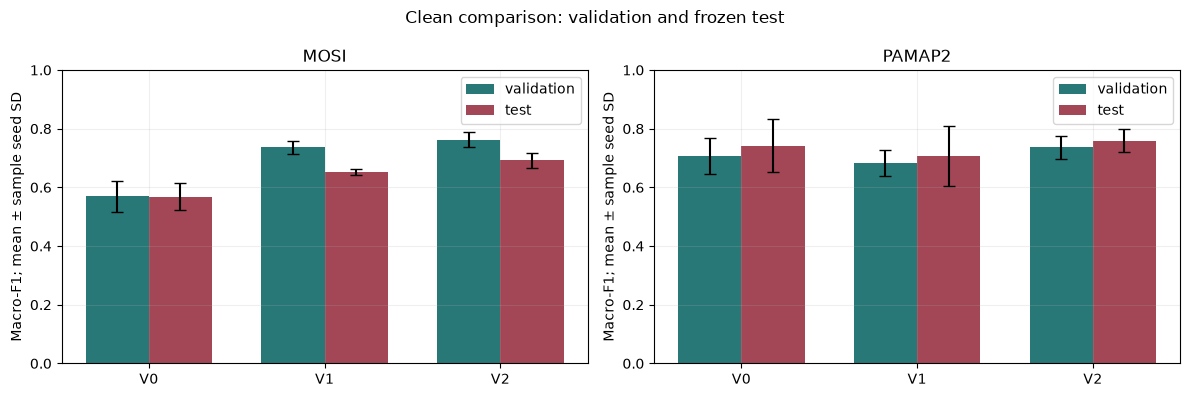

partition            test  validation  test_minus_validation
application model                                           
mosi        v0     0.5674      0.5701                -0.0027
            v1     0.6534      0.7364                -0.0830
            v2     0.6927      0.7618                -0.0691
pamap2      v0     0.7417      0.7073                 0.0344
            v1     0.7056      0.6827                 0.0229
            v2     0.7594      0.7362                 0.0232

Robustness fusion rows now carry their original parent-run temperature and calibration status.


In [4]:
METRICS = ['macro_f1','balanced_accuracy','accuracy','availability_coverage','nll','brier','ece']
aggregate_rows = []
for (application, model, partition), group in clean.groupby(['application','model','partition']):
    assert set(group.seed) == set(SEEDS)
    record = {'application': application, 'model': model, 'partition': partition, 'seeds': len(group)}
    for metric in METRICS:
        record[f'{metric}_mean'] = group[metric].mean()
        record[f'{metric}_std'] = group[metric].std(ddof=1)
    aggregate_rows.append(record)
aggregated = pd.DataFrame(aggregate_rows)
formatted = aggregated[['application','model','partition','seeds']].copy()
for metric in METRICS:
    formatted[metric] = aggregated.apply(lambda row: f"{row[f'{metric}_mean']:.4f} ± {row[f'{metric}_std']:.4f}", axis=1)
display(Markdown('### All clean aggregate results (three seeds per setting)'))
display(formatted)
fig, axes = plt.subplots(1,2,figsize=(12,4))
for axis, application in zip(axes,APPLICATIONS):
    for offset, partition, color in [(-0.18,'validation','#287878'),(0.18,'test','#a34656')]:
        rows = aggregated[(aggregated.application==application)&(aggregated.partition==partition)].set_index('model').loc[MODELS]
        axis.bar(np.arange(3)+offset,rows.macro_f1_mean,width=0.36,yerr=rows.macro_f1_std,capsize=4,label=partition,color=color)
    axis.set_xticks(range(3),[model.upper() for model in MODELS]); axis.set_ylim(0,1)
    axis.set_title(application.upper()); axis.set_ylabel('Macro-F1; mean ± sample seed SD'); axis.legend()
fig.suptitle('Clean comparison: validation and frozen test'); fig.tight_layout(); plt.show()
quality_gap = aggregated.pivot(index=['application','model'],columns='partition',values='macro_f1_mean')
quality_gap['test_minus_validation'] = quality_gap['test']-quality_gap['validation']
display(quality_gap.round(4))
lookup = run_metadata[['application','model','seed','temperature','calibration_status','fallback_mode']]
extension = extension.drop(columns=['fallback_mode'],errors='ignore').merge(lookup,on=['application','model','seed'],how='left',validate='many_to_one')
extension.loc[extension.model.str.startswith('source-'),'fallback_mode']='uncalibrated_source_reference'
extension.loc[extension.model.eq('majority'),'fallback_mode']='label_only'
unified = pd.concat([clean,extension],ignore_index=True,sort=False)
print('Robustness fusion rows now carry their original parent-run temperature and calibration status.')

## 4. Coverage and Confidence Thresholds

Availability coverage is the share of eligible decisions with a computable prediction. On the clean partitions it is 100% for every run; with all sources absent it falls to 0%. The threshold curves use saved confidence scores to show how accepted coverage and error move together. They are descriptive and do not define an operating threshold or rejection policy.

Read coverage beside Macro-F1: quality is calculated only where a prediction exists, while coverage retains the full eligible denominator. This distinction matters most for empty inputs and delayed MOSI features.


In [5]:
TABLES = {'unified_results': unified, 'clean_results': clean, 'clean_aggregates': aggregated, 'partitions': partitions, 'class_support': class_support, 'hyperparameters': hyperparameters, 'training_summary': training_summary, 'run_metadata': run_metadata}
FIGURES = {'clean_macro_f1': fig}
campaign_summary = read_json(CLEAN / 'summary.json')
assert len(campaign_summary['aggregates']) == 12
prediction_frames = {}
reliability_frames = []
for entry in plan['entries']:
    for partition in ['validation', 'test']:
        directory = CLEAN / 'results' / entry['run_id'] / partition
        frame = pd.read_parquet(directory / 'predictions.parquet')
        prediction_frames[(entry['application'], entry['model'], entry['seed'], partition)] = frame
        reliability_frame = pd.read_csv(directory / 'reliability.csv')
        reliability_frame = reliability_frame.assign(application=entry['application'], model=entry['model'], seed=entry['seed'], partition=partition)
        reliability_frames.append(reliability_frame)
coverage_denominators = clean[['application','model','seed','partition','scheduled','eligible','computable','counts.accepted','availability_coverage','accepted_coverage','selective_risk']].copy()
TABLES['coverage_denominators'] = coverage_denominators
TABLES['saved_reliability'] = pd.concat(reliability_frames, ignore_index=True)
display(Markdown('### All 36 clean denominator and coverage rows'))
display(coverage_denominators)
scenario_coverage = robust.groupby(['application','scenario'], dropna=False).agg(exports=('model','size'), eligible_min=('eligible','min'), eligible_max=('eligible','max'), computable_min=('computable','min'), computable_max=('computable','max'), coverage_min=('coverage','min'), coverage_max=('coverage','max')).reset_index()
TABLES['scenario_coverage'] = scenario_coverage
display(scenario_coverage)
print('Saved prediction fields:', list(frame.columns))
print('Saved reliability fields:', list(reliability_frame.columns))

### All 36 clean denominator and coverage rows

,application,model,seed,partition,scheduled,eligible,computable,counts.accepted,availability_coverage,accepted_coverage,selective_risk
0,mosi,v0,11,validation,117,111,111,111,1.0,1.0,0.333333
1,mosi,v0,11,test,686,656,656,656,1.0,1.0,0.390244
2,mosi,v0,22,validation,117,111,111,111,1.0,1.0,0.306306
3,mosi,v0,22,test,686,656,656,656,1.0,1.0,0.405488
4,mosi,v0,33,validation,117,111,111,111,1.0,1.0,0.342342
5,mosi,v0,33,test,686,656,656,656,1.0,1.0,0.449695
6,mosi,v1,11,validation,117,111,111,111,1.0,1.0,0.234234
7,mosi,v1,11,test,686,656,656,656,1.0,1.0,0.335366
8,mosi,v1,22,validation,117,111,111,111,1.0,1.0,0.270270
9,mosi,v1,22,test,686,656,656,656,1.0,1.0,0.344512


,application,scenario,exports,eligible_min,eligible_max,computable_min,computable_max,coverage_min,coverage_max
0,mosi,clean,19,656,656,656,656,1.0,1.0
1,mosi,delay-language-audio-visual-0.1,9,656,656,0,0,0.0,0.0
2,mosi,delay-language-audio-visual-0.25,9,656,656,0,0,0.0,0.0
3,mosi,delay-language-audio-visual-0.5,9,656,656,0,0,0.0,0.0
4,mosi,removal-language-audio-visual-0.1,9,656,656,656,656,1.0,1.0
5,mosi,removal-language-audio-visual-0.3,9,656,656,656,656,1.0,1.0
6,mosi,removal-language-audio-visual-0.5,9,656,656,656,656,1.0,1.0
7,mosi,subset-audio-visual,9,656,656,656,656,1.0,1.0
8,mosi,subset-empty,9,656,656,0,0,0.0,0.0
9,mosi,subset-language-audio,9,656,656,656,656,1.0,1.0


Saved prediction fields: ['decision_id', 'sequence_id', 'decision_time', 'support_start', 'support_end', 'target_class', 'target_time', 'score_eligible', 'exclusion_reason', 'raw_label', 'group_id', 'split', 'computable', 'predicted_class', 'confidence', 'source_presence', 'status', 'accepted', 'pred', 'scores']
Saved reliability fields: ['bin', 'lo', 'hi', 'count', 'mean_confidence', 'accuracy', 'application', 'model', 'seed', 'partition']


### Descriptive threshold snapshots: every model, seed and partition

,application,model,seed,partition,evaluation_temperature,threshold,eligible,computable,accepted,accepted_coverage,risk
0,mosi,v0,11,validation,1.00000,0.0,111,111,111,1.00000,0.33333
50,mosi,v0,11,validation,1.00000,0.5,111,111,111,1.00000,0.33333
80,mosi,v0,11,validation,1.00000,0.8,111,111,0,0.00000,NaN
90,mosi,v0,11,validation,1.00000,0.9,111,111,0,0.00000,NaN
100,mosi,v0,11,validation,1.00000,1.0,111,111,0,0.00000,NaN
101,mosi,v0,11,test,0.49590,0.0,656,656,656,1.00000,0.39024
151,mosi,v0,11,test,0.49590,0.5,656,656,656,1.00000,0.39024
181,mosi,v0,11,test,0.49590,0.8,656,656,97,0.14787,0.20619
191,mosi,v0,11,test,0.49590,0.9,656,656,18,0.02744,0.11111
201,mosi,v0,11,test,0.49590,1.0,656,656,0,0.00000,NaN


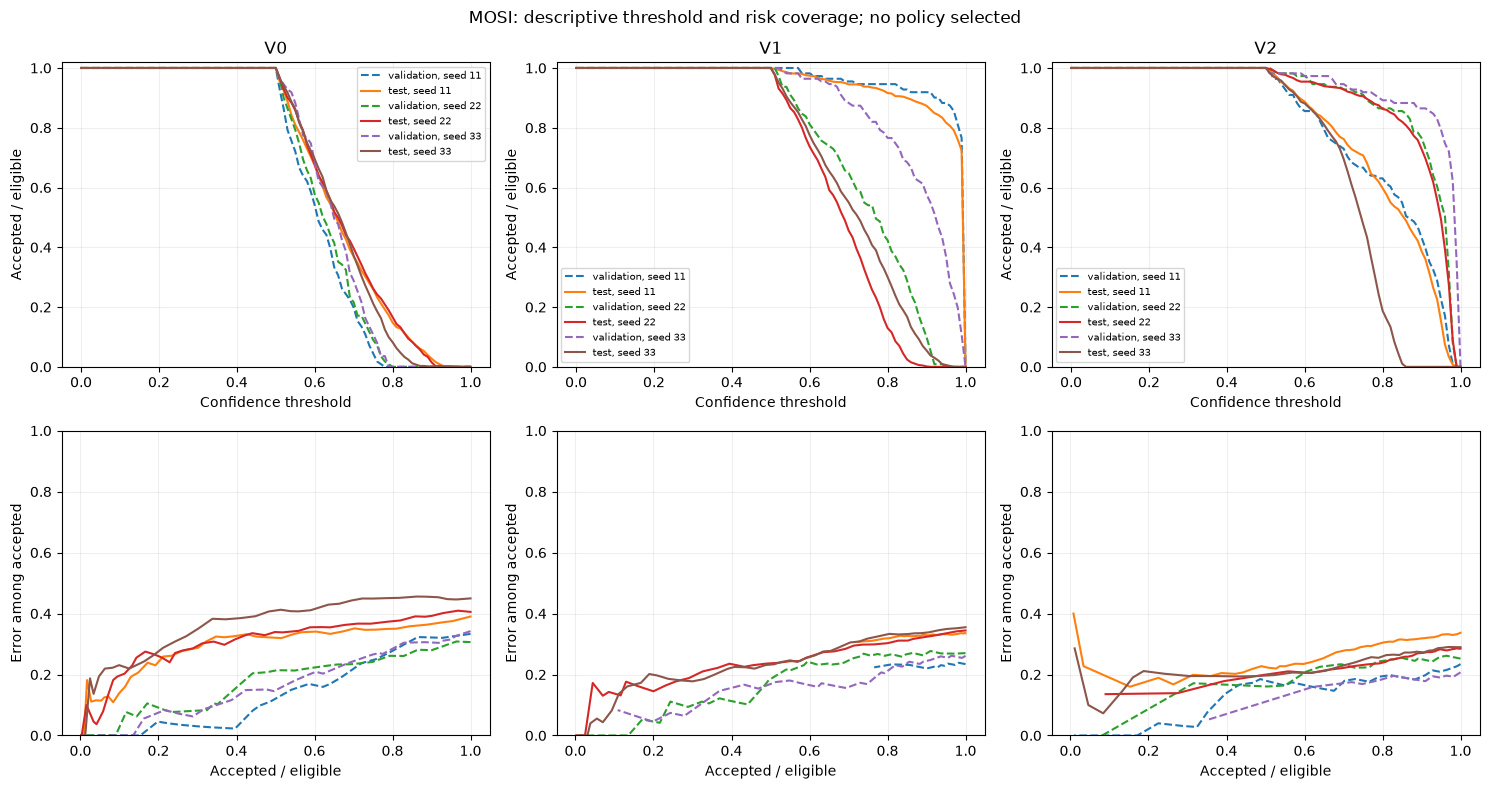

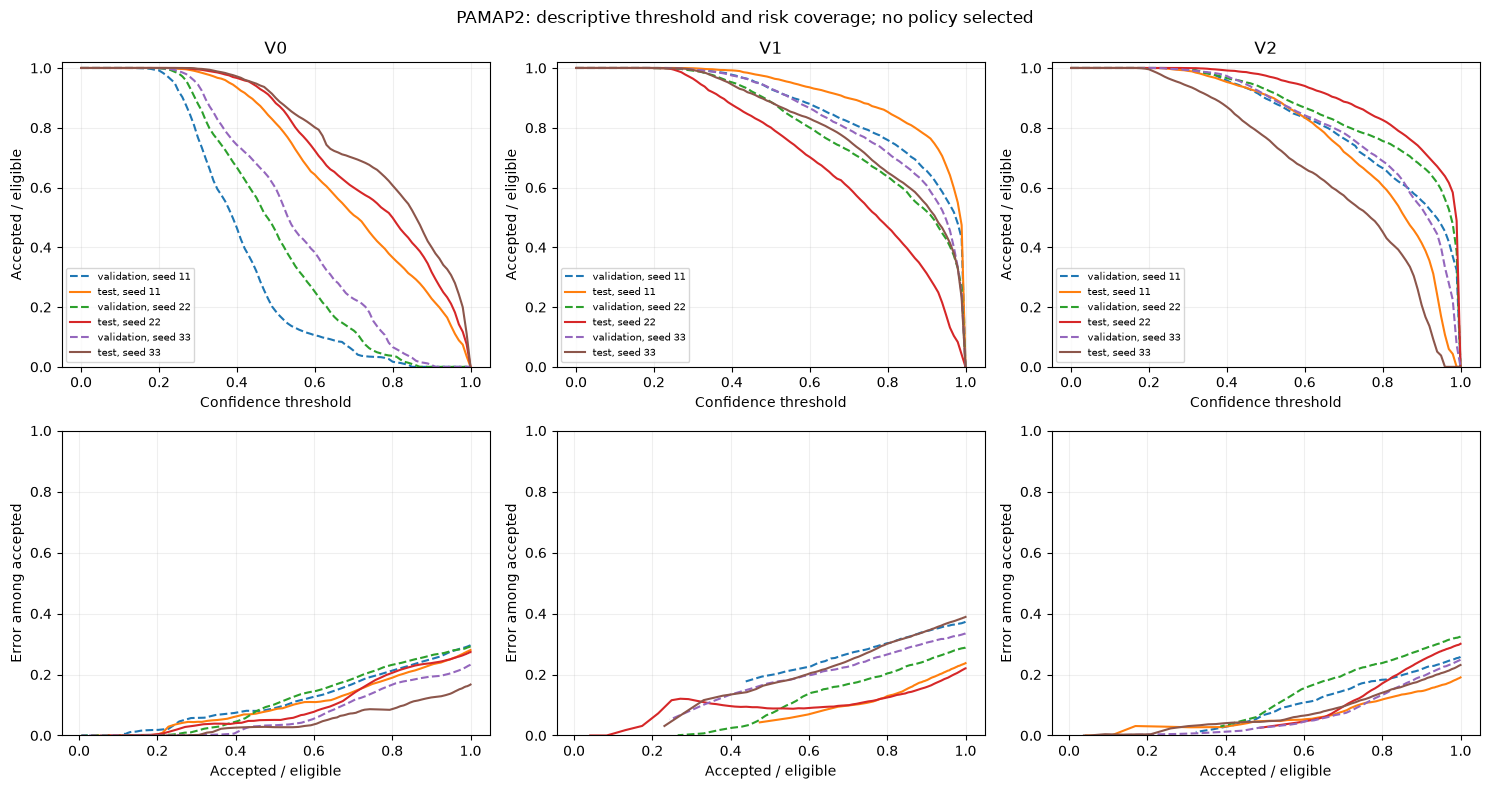

In [6]:
threshold_records = []
probability_frames = {}
for key, frame in prediction_frames.items():
    application, model, seed, partition = key
    eligible_count = int(frame.score_eligible.sum())
    selected = frame[frame.score_eligible & frame.computable].copy()
    evaluation_temperature = float(clean[(clean.application==application)&(clean.model==model)&(clean.seed==seed)&(clean.partition==partition)].evaluation_temperature.iloc[0])
    scores = np.stack([np.fromstring(value, sep=';') for value in selected.scores])
    scaled = scores / evaluation_temperature
    scaled -= scaled.max(axis=1, keepdims=True)
    probabilities = np.exp(scaled)
    probabilities /= probabilities.sum(axis=1, keepdims=True)
    assert np.allclose(probabilities.max(axis=1), selected.confidence, atol=1e-6, rtol=1e-5)
    probability_frames[key] = (selected, probabilities)
    for threshold in np.linspace(0,1,101):
        accepted_mask = selected.confidence.ge(threshold)
        accepted_count = int(accepted_mask.sum())
        risk = float((selected.loc[accepted_mask,'predicted_class'] != selected.loc[accepted_mask,'target_class']).mean()) if accepted_count else np.nan
        threshold_records.append({'application':application,'model':model,'seed':seed,'partition':partition,'evaluation_temperature':evaluation_temperature,'threshold':threshold,'eligible':eligible_count,'computable':len(selected),'accepted':accepted_count,'accepted_coverage':accepted_count/eligible_count,'risk':risk})
threshold_sweep = pd.DataFrame(threshold_records)
assert len(threshold_sweep) == 3636
TABLES['descriptive_threshold_sweep'] = threshold_sweep
display(Markdown('### Descriptive threshold snapshots: every model, seed and partition'))
display(threshold_sweep[threshold_sweep.threshold.isin([0,0.5,0.8,0.9,1])].round(5))
for application in APPLICATIONS:
    figure, plot_axes = plt.subplots(2,3,figsize=(15,8),sharex='row')
    for column, model in enumerate(MODELS):
        for seed in SEEDS:
            for partition, linestyle in [('validation','--'),('test','-')]:
                curve = threshold_sweep[(threshold_sweep.application==application)&(threshold_sweep.model==model)&(threshold_sweep.seed==seed)&(threshold_sweep.partition==partition)]
                label = f'{partition}, seed {seed}'
                plot_axes[0,column].plot(curve.threshold,curve.accepted_coverage,linestyle,label=label)
                plot_axes[1,column].plot(curve.accepted_coverage,curve.risk,linestyle,label=label)
        plot_axes[0,column].set(title=model.upper(),ylabel='Accepted / eligible',xlabel='Confidence threshold',ylim=(0,1.02))
        plot_axes[1,column].set(ylabel='Error among accepted',xlabel='Accepted / eligible',ylim=(0,1))
        plot_axes[0,column].legend(fontsize=7)
    figure.suptitle(f'{application.upper()}: descriptive threshold and risk coverage; no policy selected')
    figure.tight_layout()
    FIGURES[f'{application}_threshold_risk_coverage'] = figure
    plt.show()

## 5. Calibration Outcomes

Temperature scaling changes probability confidence without changing the predicted class order. Twelve of 18 fits succeeded; the other six retained $T=1$. The reliability plots compare validation probabilities at $T=1$ with test probabilities after the saved fit or fallback. Because validation and test contain different examples, movement between those curves cannot be attributed to calibration alone.

ECE and reliability diagrams depend on sample size and binning. They help describe confidence on these partitions, but do not establish calibration on new participants, videos or missingness conditions.

### All 18 saved temperature and optimizer diagnostic records

application,model,seed,run_id,status,saved_temperature,score_kind,optimizer,at_bound,calibration_accuracy,class_support,closure_evaluations,converged,final_grad,final_nll,initial_grad,initial_nll,iterations,missing_classes,n,termination,warning
mosi,v0,11,clean-long-20261027-run1-mosi-v0-seed-11,ok,0.495904,log_probabilities,torch LBFGS,False,0.666667,"{'0': 35, '1': 55}",5,True,-9.855604e-09,0.596810,0.045936,0.618799,2,[],90,torch LBFGS step completed,None
mosi,v0,22,clean-long-20261027-run1-mosi-v0-seed-22,ok,0.511404,log_probabilities,torch LBFGS,False,0.711111,"{'0': 35, '1': 55}",5,True,-2.907660e-09,0.594408,0.046905,0.615566,2,[],90,torch LBFGS step completed,None
mosi,v0,33,clean-long-20261027-run1-mosi-v0-seed-33,ok,0.686934,log_probabilities,torch LBFGS,False,0.666667,"{'0': 35, '1': 55}",5,True,1.880978e-07,0.613336,0.032041,0.620455,4,[],90,torch LBFGS step completed,None
mosi,v1,11,clean-long-20261027-run1-mosi-v1-seed-11,fit_failed,1.000000,logits,torch LBFGS,False,0.666667,"{'0': 35, '1': 55}",12,False,4.080649e-06,0.624540,-2.115146,2.216670,5,[],90,torch LBFGS step completed,None
mosi,v1,22,clean-long-20261027-run1-mosi-v1-seed-22,ok,1.419088,logits,torch LBFGS,False,0.655556,"{'0': 35, '1': 55}",7,True,2.136247e-07,0.610482,-0.071163,0.621511,6,[],90,torch LBFGS step completed,None
mosi,v1,33,clean-long-20261027-run1-mosi-v1-seed-33,ok,2.214030,logits,torch LBFGS,False,0.711111,"{'0': 35, '1': 55}",9,True,-1.244917e-08,0.549583,-0.320969,0.656137,5,[],90,torch LBFGS step completed,None
mosi,v2,11,clean-long-20261027-run1-mosi-v2-seed-11,fit_failed,1.000000,logits,torch LBFGS,False,0.688889,"{'0': 35, '1': 55}",8,False,-1.728926e-06,0.565553,-0.122300,0.588766,7,[],90,torch LBFGS step completed,None
mosi,v2,22,clean-long-20261027-run1-mosi-v2-seed-22,fit_failed,1.000000,logits,torch LBFGS,False,0.677778,"{'0': 35, '1': 55}",12,False,2.916894e-06,0.587767,-0.566300,0.822847,5,[],90,torch LBFGS step completed,None
mosi,v2,33,clean-long-20261027-run1-mosi-v2-seed-33,ok,3.780332,logits,torch LBFGS,False,0.711111,"{'0': 35, '1': 55}",13,True,-2.736940e-07,0.571372,-0.807781,0.980319,6,[],90,torch LBFGS step completed,None
pamap2,v0,11,clean-long-20261027-run1-pamap2-v0-seed-11,ok,0.378405,log_probabilities,torch LBFGS,False,0.721099,"{'0': 242, '1': 229, '10': 330, '11': 88, '2': 251, '3': 316, '4': 166, '5': 254, '6': 289, '7': 117, '8': 96, '9': 243}",7,True,-5.461661e-08,0.923170,0.572895,1.256179,6,[],2621,torch LBFGS step completed,None


### Original validation T=1 versus frozen test saved T (36 rows)

,application,model,seed,partition,fitted_temperature,evaluation_temperature,calibration_status,nll,brier,ece,probability.mean_confidence
0,mosi,v0,11,validation,0.49590,1.00000,ok,0.57641,0.38960,0.13587,0.61492
1,mosi,v0,11,test,0.49590,0.49590,ok,0.65942,0.46627,0.06563,0.66877
2,mosi,v0,22,validation,0.51140,1.00000,ok,0.58818,0.40097,0.07430,0.62819
3,mosi,v0,22,test,0.51140,0.51140,ok,0.67354,0.47929,0.08261,0.67333
4,mosi,v0,33,validation,0.68693,1.00000,ok,0.58481,0.39887,0.11612,0.64701
5,mosi,v0,33,test,0.68693,0.68693,ok,0.71148,0.51586,0.12674,0.66286
6,mosi,v1,11,validation,1.00000,1.00000,fit_failed,1.62278,0.44907,0.21891,0.96932
7,mosi,v1,11,test,1.00000,1.00000,fit_failed,2.17296,0.62735,0.30108,0.95780
8,mosi,v1,22,validation,1.41909,1.00000,ok,0.56414,0.38619,0.11341,0.74648
9,mosi,v1,22,test,1.41909,1.41909,ok,0.61223,0.42447,0.03829,0.68111


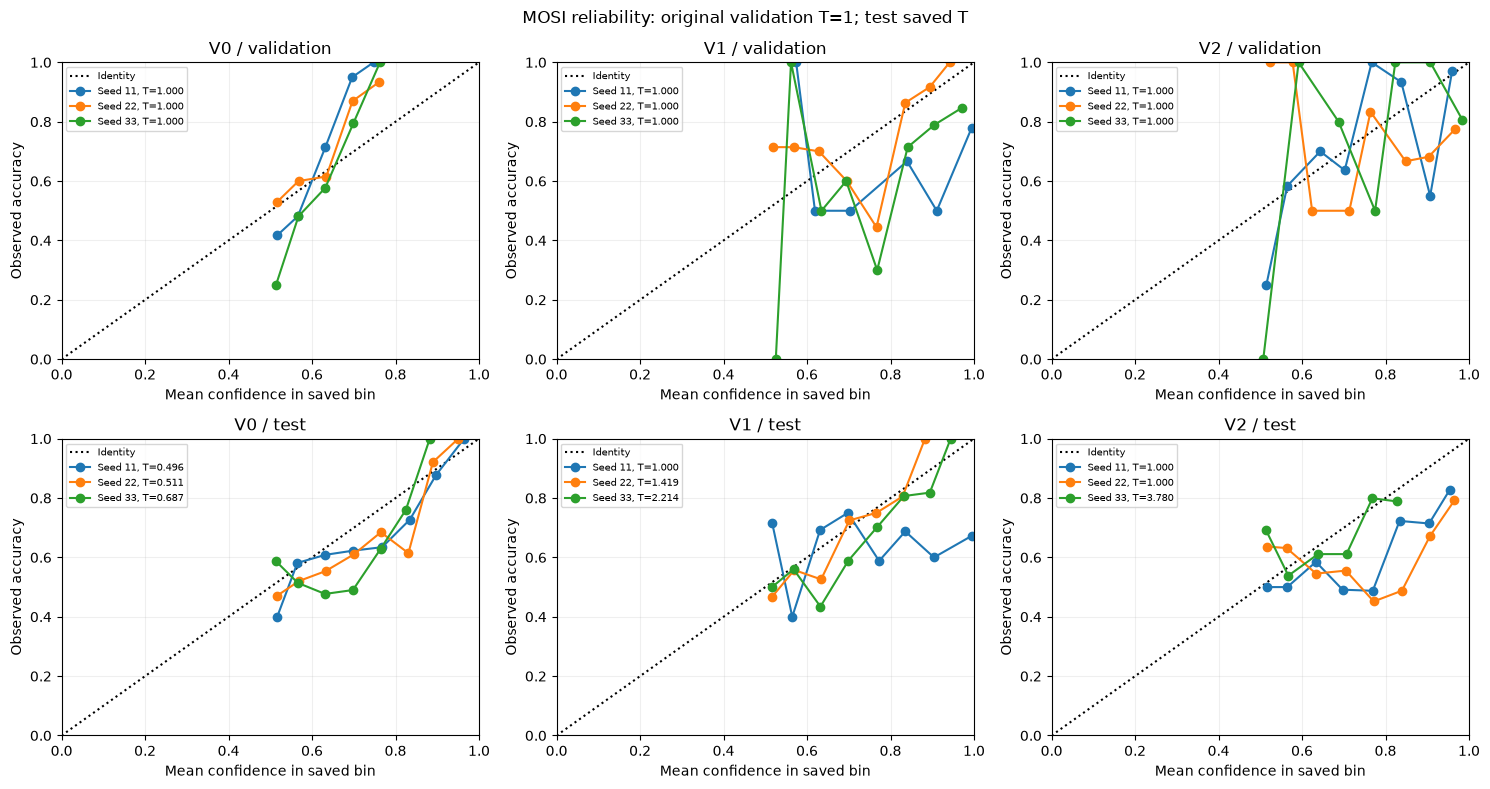

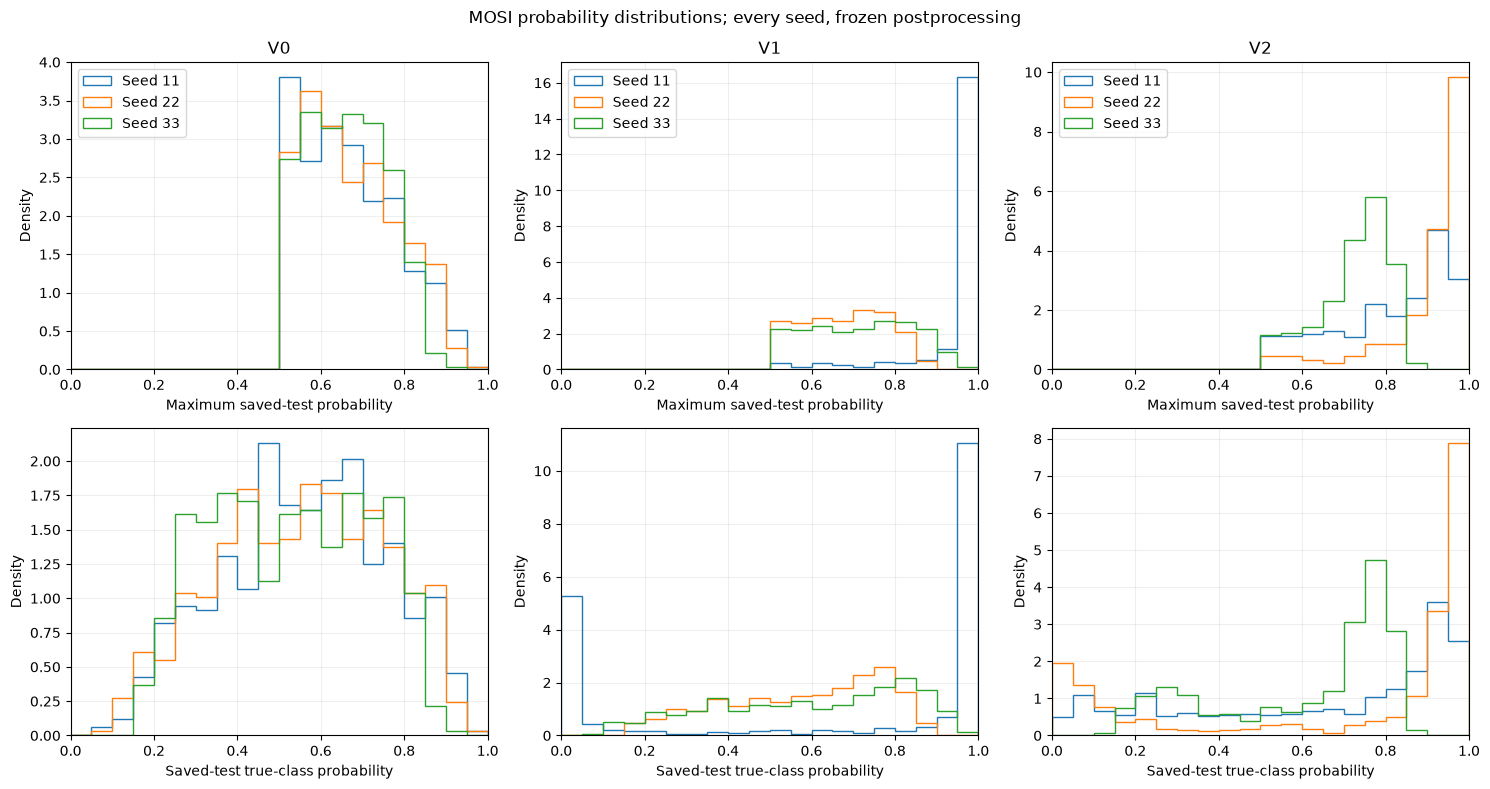

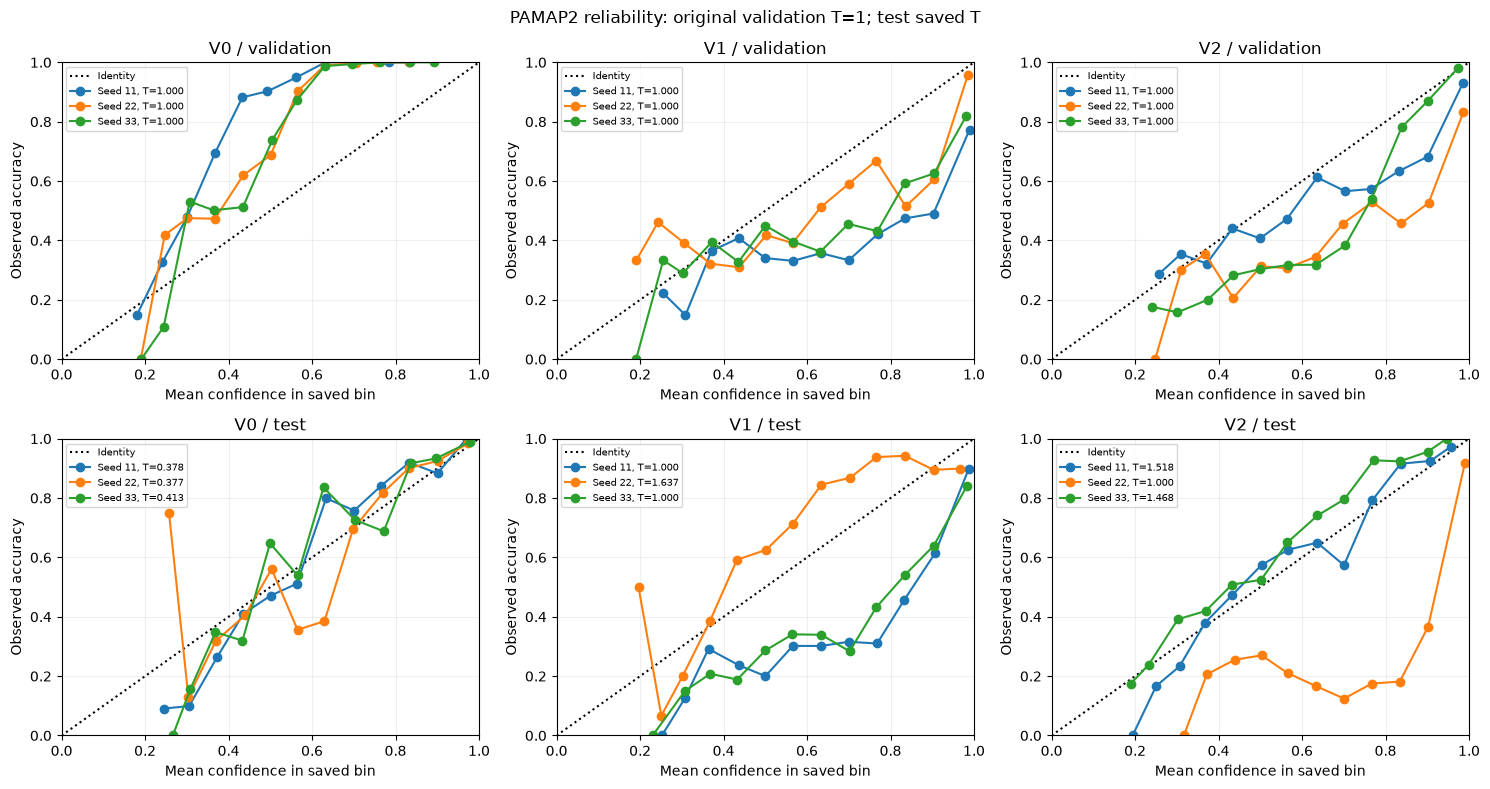

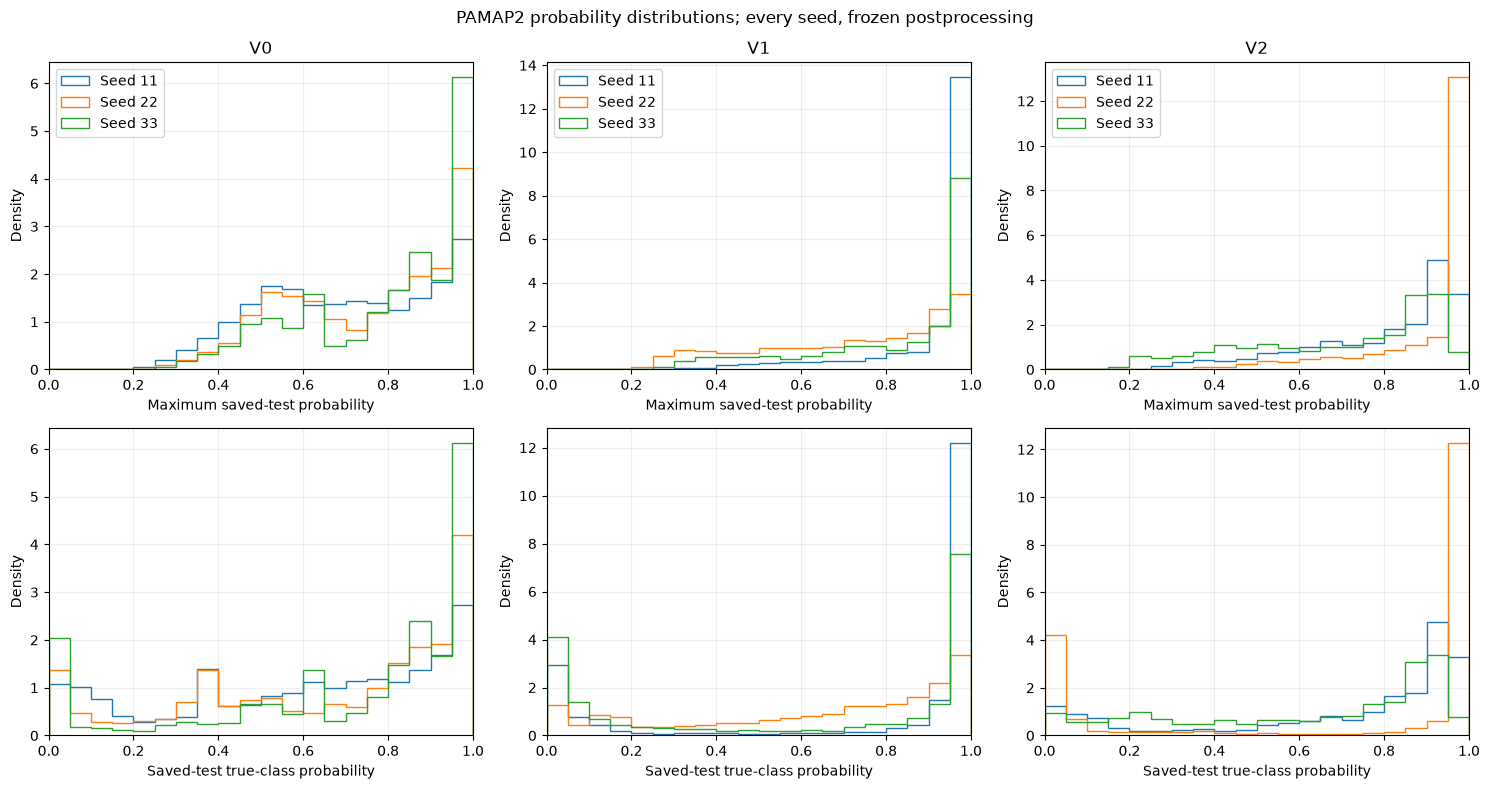

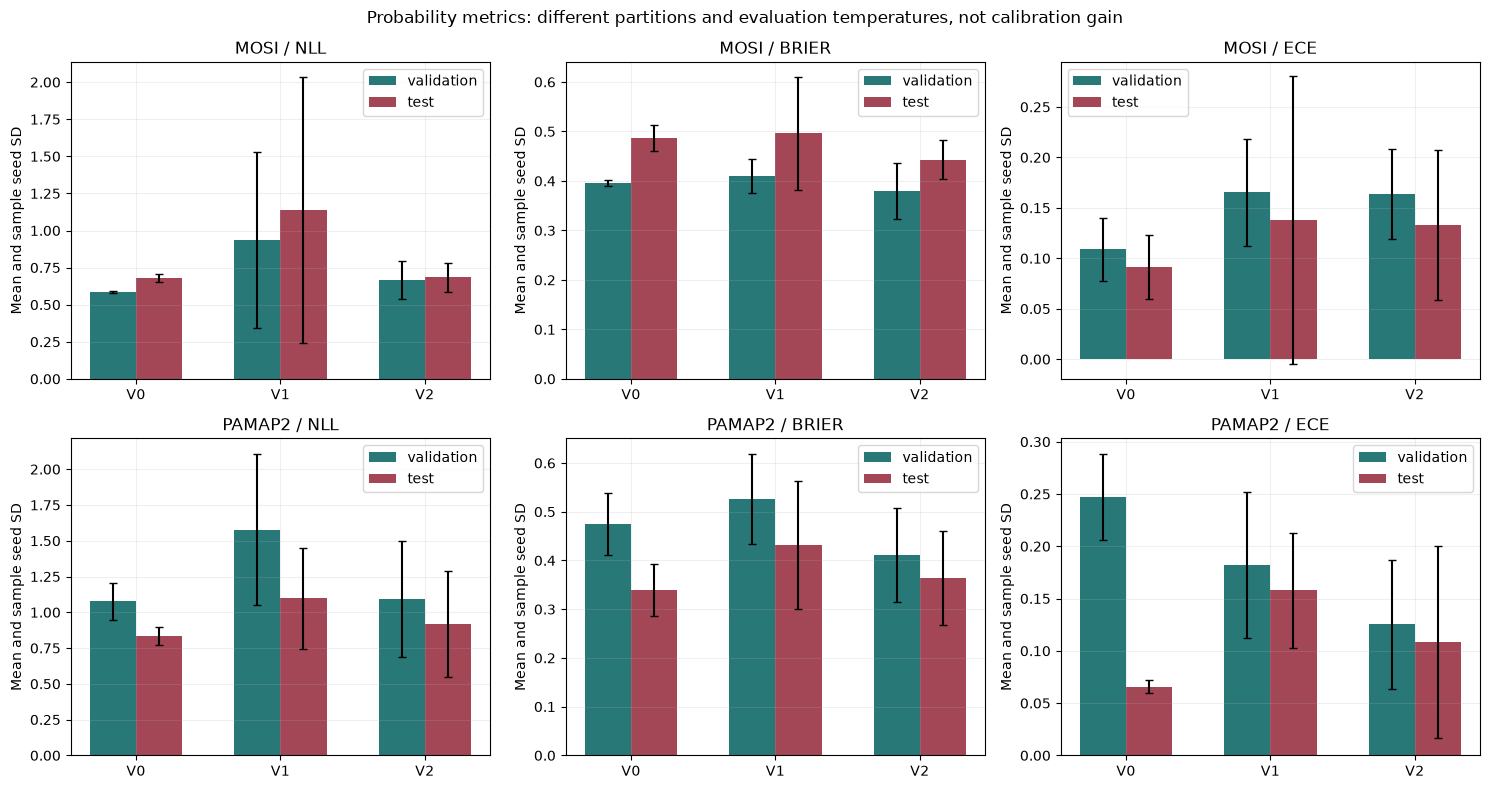

In [7]:
from IPython.display import HTML
calibration_records = []
for entry in plan['entries']:
    artifact = read_json(CLEAN / 'results' / entry['run_id'] / 'calibration.json')
    calibration_records.append({'application':entry['application'],'model':entry['model'],'seed':entry['seed'],'run_id':entry['run_id'],'status':artifact['status'],'saved_temperature':artifact['T'],'score_kind':artifact['score_kind'],'optimizer':artifact['optimizer'],**artifact['diagnostics']})
calibration_diagnostics = pd.DataFrame(calibration_records)
assert len(calibration_diagnostics)==18
TABLES['calibration_diagnostics'] = calibration_diagnostics
display(Markdown('### All 18 saved temperature and optimizer diagnostic records'))
display(HTML(calibration_diagnostics.to_html(index=False, max_rows=None, max_cols=None)))
probability_metrics = clean[['application','model','seed','partition','fitted_temperature','evaluation_temperature','calibration_status','nll','brier','ece','probability.mean_confidence']].copy()
TABLES['probability_metrics'] = probability_metrics
display(Markdown('### Original validation T=1 versus frozen test saved T (36 rows)'))
display(probability_metrics.round(5))
reliability = TABLES['saved_reliability']
for application in APPLICATIONS:
    figure, plot_axes = plt.subplots(2,3,figsize=(15,8))
    for row_index, partition in enumerate(['validation','test']):
        for column, model in enumerate(MODELS):
            axis = plot_axes[row_index,column]
            axis.plot([0,1],[0,1],color='black',linestyle=':',label='Identity')
            for seed in SEEDS:
                bins = reliability[(reliability.application==application)&(reliability.model==model)&(reliability.seed==seed)&(reliability.partition==partition)&(reliability['count']>0)]
                temperature = probability_metrics[(probability_metrics.application==application)&(probability_metrics.model==model)&(probability_metrics.seed==seed)&(probability_metrics.partition==partition)].evaluation_temperature.iloc[0]
                axis.plot(bins.mean_confidence,bins.accuracy,marker='o',label=f'Seed {seed}, T={temperature:.3f}')
            axis.set(title=f'{model.upper()} / {partition}',xlabel='Mean confidence in saved bin',ylabel='Observed accuracy',xlim=(0,1),ylim=(0,1)); axis.legend(fontsize=7)
    figure.suptitle(f'{application.upper()} reliability: original validation T=1; test saved T')
    figure.tight_layout(); FIGURES[f'{application}_reliability'] = figure; plt.show()
    figure, plot_axes = plt.subplots(2,3,figsize=(15,8))
    for column, model in enumerate(MODELS):
        for seed in SEEDS:
            selected, probabilities = probability_frames[(application,model,seed,'test')]
            true_probability = probabilities[np.arange(len(selected)),selected.target_class.to_numpy(dtype=int)]
            plot_axes[0,column].hist(probabilities.max(axis=1),bins=np.linspace(0,1,21),density=True,histtype='step',label=f'Seed {seed}')
            plot_axes[1,column].hist(true_probability,bins=np.linspace(0,1,21),density=True,histtype='step',label=f'Seed {seed}')
        plot_axes[0,column].set(title=model.upper(),xlabel='Maximum saved-test probability',ylabel='Density',xlim=(0,1))
        plot_axes[1,column].set(xlabel='Saved-test true-class probability',ylabel='Density',xlim=(0,1)); plot_axes[0,column].legend()
    figure.suptitle(f'{application.upper()} probability distributions; every seed, frozen postprocessing')
    figure.tight_layout(); FIGURES[f'{application}_probability_distributions'] = figure; plt.show()
figure, plot_axes = plt.subplots(2,3,figsize=(15,8))
for row_index, application in enumerate(APPLICATIONS):
    for column, metric in enumerate(['nll','brier','ece']):
        axis = plot_axes[row_index,column]
        for partition, shift, color in [('validation',-0.16,'#287878'),('test',0.16,'#a34656')]:
            rows = aggregated[(aggregated.application==application)&(aggregated.partition==partition)].set_index('model').loc[MODELS]
            axis.bar(np.arange(3)+shift,rows[f'{metric}_mean'],width=0.32,yerr=rows[f'{metric}_std'],capsize=3,label=partition,color=color)
        axis.set(title=f'{application.upper()} / {metric.upper()}',ylabel='Mean and sample seed SD')
        axis.set_xticks(range(3),[model.upper() for model in MODELS]); axis.legend()
figure.suptitle('Probability metrics: different partitions and evaluation temperatures, not calibration gain')
figure.tight_layout(); FIGURES['probability_metrics'] = figure; plt.show()

### Six identity-temperature fallbacks

The failed fits are MOSI V1 seed 11, V2 seeds 11 and 22, and PAMAP2 V1 seeds 11 and 33, plus V2 seed 22. Each retained $T=1$ and remains in the reported model averages. For these runs, confidence metrics describe uncalibrated scores; their classification results are still included.

All 18 abstention policies have no threshold because operating risk and coverage constraints were not specified. Accepted coverage therefore matches availability coverage; the threshold curves above are not an evaluated rejection policy.

In [8]:
fallbacks = calibration_diagnostics[calibration_diagnostics.status.eq('fit_failed')].copy()
assert len(fallbacks)==6 and fallbacks.saved_temperature.eq(1).all() and (~fallbacks.converged).all()
fallback_test = fallbacks.merge(clean[clean.partition.eq('test')][['run_id','macro_f1','nll','brier','ece','evaluation_temperature','availability_coverage']],on='run_id',validate='one_to_one')
TABLES['six_fallbacks'] = fallback_test
display(HTML(fallback_test.to_html(index=False,max_rows=None,max_cols=None)))
policy_records = []
for entry in plan['entries']:
    policy_artifact = read_json(CLEAN / 'results' / entry['run_id'] / 'policy.json')
    policy_records.append({'application':entry['application'],'model':entry['model'],'seed':entry['seed'],'run_id':entry['run_id'],'status':policy_artifact['status'],'threshold':policy_artifact['tau'],'saved_policy':json.dumps(policy_artifact,sort_keys=True)})
policies = pd.DataFrame(policy_records)
assert len(policies)==18 and policies.status.eq('disabled_no_constraints').all() and policies.threshold.isna().all()
TABLES['disabled_policies'] = policies
display(Markdown('### All 18 frozen abstention policies'))
display(policies.drop(columns='saved_policy'))
print('Attempted-fit initial/final NLL and gradients above are optimizer diagnostics, not substituted fallback evaluation metrics.')

application,model,seed,run_id,status,saved_temperature,score_kind,optimizer,at_bound,calibration_accuracy,class_support,closure_evaluations,converged,final_grad,final_nll,initial_grad,initial_nll,iterations,missing_classes,n,termination,warning,macro_f1,nll,brier,ece,evaluation_temperature,availability_coverage
mosi,v1,11,clean-long-20261027-run1-mosi-v1-seed-11,fit_failed,1.0,logits,torch LBFGS,False,0.666667,"{'0': 35, '1': 55}",12,False,0.000004,0.624540,-2.115146,2.216670,5,[],90,torch LBFGS step completed,None,0.664622,2.172959,0.627345,0.301081,1.0,1.0
mosi,v2,11,clean-long-20261027-run1-mosi-v2-seed-11,fit_failed,1.0,logits,torch LBFGS,False,0.688889,"{'0': 35, '1': 55}",8,False,-0.000002,0.565553,-0.122300,0.588766,7,[],90,torch LBFGS step completed,None,0.662977,0.695366,0.464446,0.148880,1.0,1.0
mosi,v2,22,clean-long-20261027-run1-mosi-v2-seed-22,fit_failed,1.0,logits,torch LBFGS,False,0.677778,"{'0': 35, '1': 55}",12,False,0.000003,0.587767,-0.566300,0.822847,5,[],90,torch LBFGS step completed,None,0.709594,0.771688,0.467713,0.197542,1.0,1.0
pamap2,v1,11,clean-long-20261027-run1-pamap2-v1-seed-11,fit_failed,1.0,logits,torch LBFGS,False,0.652041,"{'0': 242, '1': 229, '10': 330, '11': 88, '2': 251, '3': 316, '4': 166, '5': 254, '6': 289, '7': 117, '8': 96, '9': 243}",7,False,0.000029,1.016441,-0.987314,1.371880,6,[],2621,torch LBFGS step completed,None,0.759393,1.036330,0.380893,0.155307,1.0,1.0
pamap2,v1,33,clean-long-20261027-run1-pamap2-v1-seed-33,fit_failed,1.0,logits,torch LBFGS,False,0.598626,"{'0': 242, '1': 229, '10': 330, '11': 88, '2': 251, '3': 316, '4': 166, '5': 254, '6': 289, '7': 117, '8': 96, '9': 243}",8,False,-0.000003,1.125220,-0.777093,1.326582,7,[],2621,torch LBFGS step completed,None,0.587233,1.472915,0.581911,0.214333,1.0,1.0
pamap2,v2,22,clean-long-20261027-run1-pamap2-v2-seed-22,fit_failed,1.0,logits,torch LBFGS,False,0.449065,"{'0': 242, '1': 229, '10': 330, '11': 88, '2': 251, '3': 316, '4': 166, '5': 254, '6': 289, '7': 117, '8': 96, '9': 243}",13,False,-0.000005,1.767644,-2.881718,3.252423,4,[],2621,torch LBFGS step completed,None,0.715807,1.345578,0.473409,0.212236,1.0,1.0


### All 18 frozen abstention policies

,application,model,seed,run_id,status,threshold
0,mosi,v0,11,clean-long-20261027-run1-mosi-v0-seed-11,disabled_no_constraints,None
1,mosi,v0,22,clean-long-20261027-run1-mosi-v0-seed-22,disabled_no_constraints,None
2,mosi,v0,33,clean-long-20261027-run1-mosi-v0-seed-33,disabled_no_constraints,None
3,mosi,v1,11,clean-long-20261027-run1-mosi-v1-seed-11,disabled_no_constraints,None
4,mosi,v1,22,clean-long-20261027-run1-mosi-v1-seed-22,disabled_no_constraints,None
5,mosi,v1,33,clean-long-20261027-run1-mosi-v1-seed-33,disabled_no_constraints,None
6,mosi,v2,11,clean-long-20261027-run1-mosi-v2-seed-11,disabled_no_constraints,None
7,mosi,v2,22,clean-long-20261027-run1-mosi-v2-seed-22,disabled_no_constraints,None
8,mosi,v2,33,clean-long-20261027-run1-mosi-v2-seed-33,disabled_no_constraints,None
9,pamap2,v0,11,clean-long-20261027-run1-pamap2-v0-seed-11,disabled_no_constraints,None


Attempted-fit initial/final NLL and gradients above are optimizer diagnostics, not substituted fallback evaluation metrics.


## 6. Baselines and Paired Comparisons

The majority baseline uses eligible training labels and returns labels without confidence scores. Source-only baselines reuse the selected V0 source classifiers; their probabilities are uncalibrated. On clean test data, language-only MOSI reaches Macro-F1 0.6548, close to V1's 0.6534. PAMAP2 source-only means range from 0.2498 for heart rate to 0.6316 for hand, compared with 0.0170 for majority.

The 204 paired comparisons use the saved 1,000-draw group bootstrap (seed 2026), pairing models on common computable decisions. Intervals are conditional on each training seed. PAMAP2 has only two test participants, making its group intervals especially unstable; they should be read as descriptive uncertainty, not a significance test.

### Complete clean fusion, majority and source-only references (41 rows)

application,scenario,kind,severity,model,seed,macro_f1,balanced_accuracy,coverage,eligible,computable,nll,brier,ece,seconds,schedule_hash,rows_removed,closure_availability_test
mosi,clean,clean,null,v0,11,0.603562,0.644781,1.0,656,656,0.659417,0.466270,0.065625,10.012074,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-language,11,0.677382,0.678958,1.0,656,656,0.589858,0.406828,0.044146,8.516949,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-audio,11,0.402287,0.534582,1.0,656,656,0.713468,0.519761,0.102626,9.505690,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-visual,11,0.499913,0.552923,1.0,656,656,0.795685,0.583842,0.170768,9.323008,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,majority,11,0.296892,0.500000,1.0,656,656,null,null,null,9.790724,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,v0,22,0.582781,0.635960,1.0,656,656,0.673541,0.479288,0.082613,10.040950,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-language,22,0.691099,0.696451,1.0,656,656,0.592448,0.407621,0.055019,9.947444,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-audio,22,0.296892,0.500000,1.0,656,656,0.750710,0.556110,0.192606,9.863265,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-visual,22,0.497173,0.555352,1.0,656,656,0.750531,0.549426,0.124890,8.588548,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,v0,33,0.515850,0.606446,1.0,656,656,0.711475,0.515858,0.126736,9.450104,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False


### Baseline means; majority has one deterministic row and null seed SD (15 rows)

application,model,rows,macro_f1_mean,macro_f1_seed_sd,balanced_accuracy_mean,coverage
mosi,majority,1,0.296892,null,0.500000,1.0
mosi,source-audio,3,0.332024,0.060850,0.511527,1.0
mosi,source-language,3,0.654821,0.051416,0.673211,1.0
mosi,source-visual,3,0.498824,0.001454,0.553894,1.0
mosi,v0,3,0.567398,0.045835,0.629062,1.0
mosi,v1,3,0.653396,0.010255,0.663353,1.0
mosi,v2,3,0.692703,0.025823,0.700431,1.0
pamap2,majority,1,0.016973,null,0.083333,1.0
pamap2,source-ankle,3,0.515584,0.196013,0.537998,1.0
pamap2,source-chest,3,0.504803,0.042849,0.494373,1.0


### Source checkpoint internal seeds (21 rows)

application,nominal_seed,source,internal_source_seed
mosi,11,language,11
mosi,11,audio,12
mosi,11,visual,13
mosi,22,language,22
mosi,22,audio,23
mosi,22,visual,24
mosi,33,language,33
mosi,33,audio,34
mosi,33,visual,35
pamap2,11,hand,11


### All saved paired bootstrap comparisons, with original coverage (204 rows)

application,scenario,seed,model,reference,common_decisions,groups,difference_macro_f1,difference_balanced_accuracy,balanced_ci_low,balanced_ci_high,ci_low,ci_high,valid_replicates,status,warning,model_coverage,reference_coverage
mosi,clean,11,majority,v0,656,31,-0.306670,-0.144781,-0.195655,-0.093486,-0.376628,-0.233883,1000,ok,ok,1.0,1.0
mosi,clean,11,source-audio,v0,656,31,-0.201274,-0.110199,-0.162909,-0.049140,-0.268943,-0.119398,1000,ok,ok,1.0,1.0
mosi,clean,11,source-audio,majority,656,31,0.105396,0.034582,0.012970,0.057156,0.063449,0.145046,1000,ok,ok,1.0,1.0
mosi,clean,11,source-language,v0,656,31,0.073820,0.034177,-0.016941,0.083960,0.016677,0.133174,1000,ok,ok,1.0,1.0
mosi,clean,11,source-language,majority,656,31,0.380490,0.178958,0.140569,0.215172,0.326766,0.428293,1000,ok,ok,1.0,1.0
mosi,clean,11,source-visual,v0,656,31,-0.103649,-0.091858,-0.148792,-0.042877,-0.179590,-0.047191,1000,ok,ok,1.0,1.0
mosi,clean,11,source-visual,majority,656,31,0.203021,0.052923,-0.020960,0.130705,0.090732,0.310618,1000,ok,ok,1.0,1.0
mosi,clean,11,v0,majority,656,31,0.306670,0.144781,0.093486,0.195655,0.233883,0.376628,1000,ok,ok,1.0,1.0
mosi,clean,11,v1,v0,656,31,0.061060,0.035349,-0.009598,0.077748,0.010781,0.110286,1000,ok,ok,1.0,1.0
mosi,clean,11,v1,majority,656,31,0.367730,0.180129,0.132443,0.221112,0.305833,0.418766,1000,ok,ok,1.0,1.0


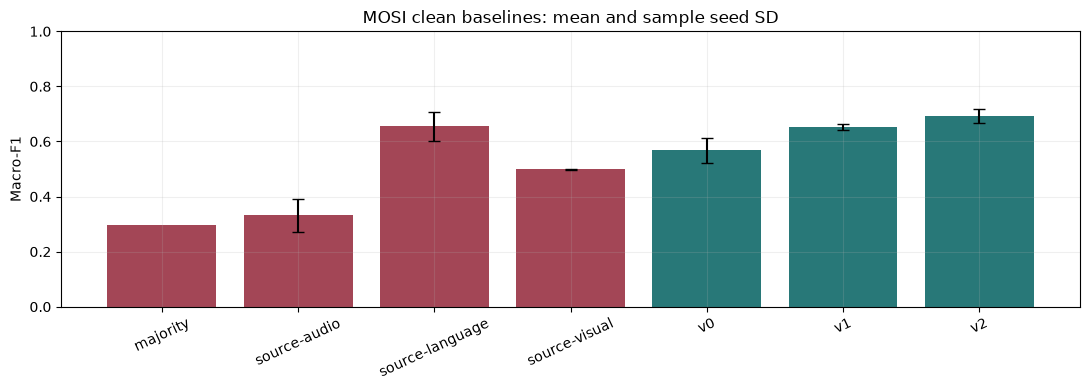

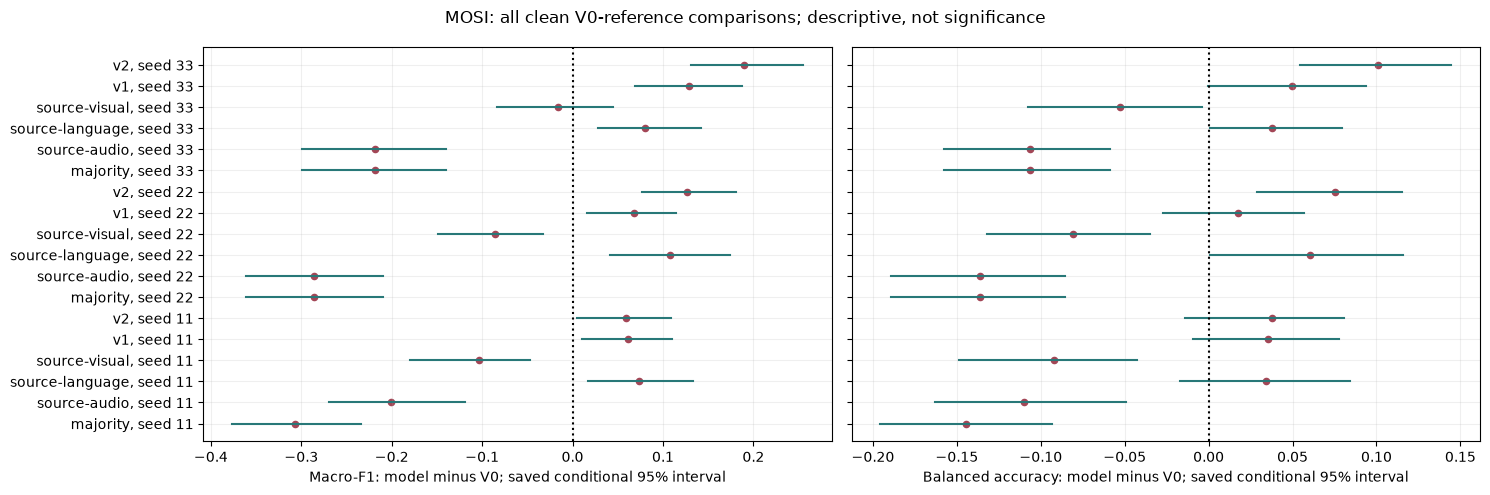

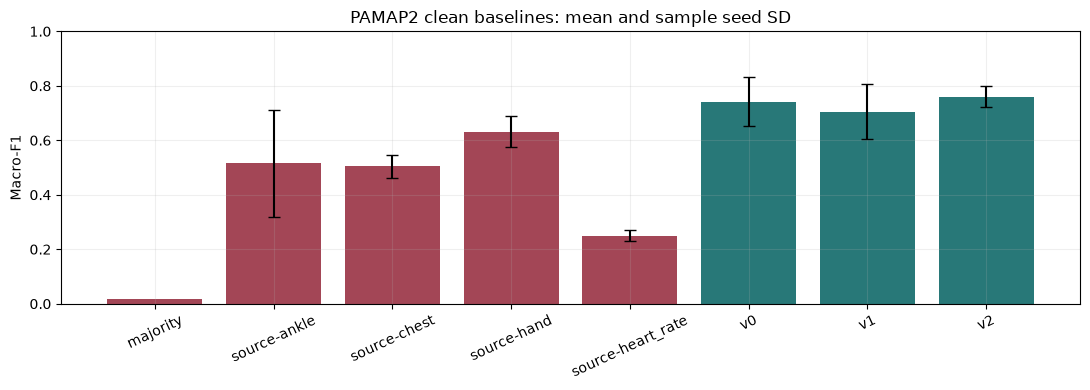

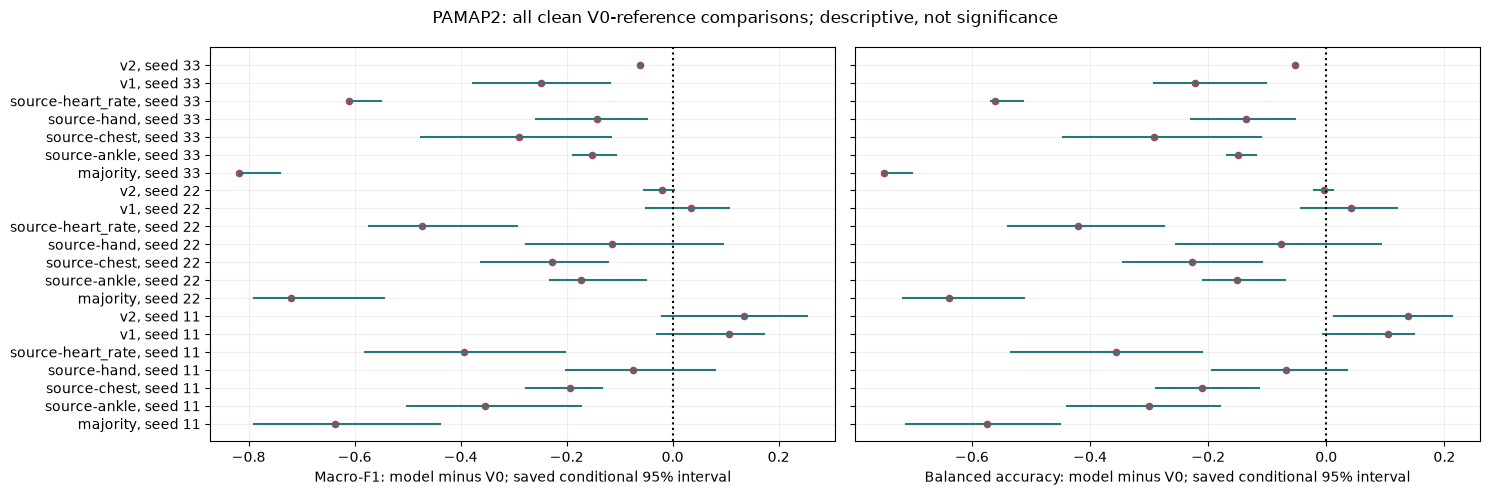

In [9]:
def show_complete(table, title):
    display(Markdown(f'### {title} ({len(table)} rows)'))
    display(HTML('<div style="overflow-x:auto">'+table.to_html(index=False,max_rows=None,max_cols=None,na_rep='null')+'</div>'))
clean_baselines = robust[robust.scenario.eq('clean')].copy()
assert len(clean_baselines)==41
TABLES['clean_baselines_all_seeds'] = clean_baselines
show_complete(clean_baselines,'Complete clean fusion, majority and source-only references')
baseline_aggregates = clean_baselines.groupby(['application','model']).agg(rows=('macro_f1','size'),macro_f1_mean=('macro_f1','mean'),macro_f1_seed_sd=('macro_f1','std'),balanced_accuracy_mean=('balanced_accuracy','mean'),coverage=('coverage','mean')).reset_index()
TABLES['baseline_aggregates'] = baseline_aggregates
show_complete(baseline_aggregates,'Baseline means; majority has one deterministic row and null seed SD')
baseline_provenance = read_json(STUDY / 'baseline_provenance.json')
majority_provenance = read_json(STUDY / 'majority_provenance.json')
TABLES['baseline_provenance'] = pd.json_normalize(baseline_provenance)
TABLES['majority_provenance'] = pd.json_normalize(majority_provenance)
source_seed_records = []
for entry in plan['entries']:
    if entry['model']=='v0':
        for source_index, source in enumerate(model_metadata[entry['run_id']]['source_order']):
            source_seed_records.append({'application':entry['application'],'nominal_seed':entry['seed'],'source':source,'internal_source_seed':entry['seed']+source_index})
source_seeds = pd.DataFrame(source_seed_records)
assert len(source_seeds)==21
TABLES['source_internal_seeds'] = source_seeds
show_complete(source_seeds,'Source checkpoint internal seeds')
def original_coverage(application,scenario,model,seed):
    candidates = robust[(robust.application==application)&(robust.scenario==scenario)&(robust.model==model)]
    if model!='majority':
        candidates = candidates[candidates.seed.eq(seed)]
    assert len(candidates)==1
    return float(candidates.coverage.iloc[0])
paired_report = paired.copy()
paired_report['model_coverage'] = [original_coverage(row.application,row.scenario,row.model,row.seed) for row in paired.itertuples(index=False)]
paired_report['reference_coverage'] = [original_coverage(row.application,row.scenario,row.reference,row.seed) for row in paired.itertuples(index=False)]
assert len(paired_report)==204
TABLES['paired_comparisons_204'] = paired_report
show_complete(paired_report,'All saved paired bootstrap comparisons, with original coverage')
for application in APPLICATIONS:
    rows = baseline_aggregates[baseline_aggregates.application.eq(application)]
    figure, axis = plt.subplots(figsize=(11,4))
    axis.bar(rows.model,rows.macro_f1_mean,color=['#287878' if model.startswith('v') else '#a34656' for model in rows.model])
    seed_rows = rows[rows.rows.gt(1)]
    positions = [list(rows.model).index(model) for model in seed_rows.model]
    axis.errorbar(positions,seed_rows.macro_f1_mean,yerr=seed_rows.macro_f1_seed_sd,fmt='none',ecolor='black',capsize=4)
    axis.set(title=f'{application.upper()} clean baselines: mean and sample seed SD',ylabel='Macro-F1',ylim=(0,1))
    axis.tick_params(axis='x',rotation=25); figure.tight_layout(); FIGURES[f'{application}_clean_baseline_comparison']=figure; plt.show()
    comparisons = paired_report[(paired_report.application==application)&(paired_report.scenario=='clean')&(paired_report.reference=='v0')].copy()
    figure, plot_axes = plt.subplots(1,2,figsize=(15,max(5,len(comparisons)*0.22)),sharey=True)
    labels = [f'{row.model}, seed {row.seed}' for row in comparisons.itertuples(index=False)]
    for axis, difference, lower, upper, metric_label in [(plot_axes[0],'difference_macro_f1','ci_low','ci_high','Macro-F1'),(plot_axes[1],'difference_balanced_accuracy','balanced_ci_low','balanced_ci_high','Balanced accuracy')]:
        for position, row in enumerate(comparisons.to_dict('records')):
            if pd.notna(row[difference]):
                axis.plot([row[lower],row[upper]],[position,position],color='#287878')
                axis.scatter(row[difference],position,color='#a34656',s=20)
        axis.axvline(0,color='black',linestyle=':'); axis.set_xlabel(f'{metric_label}: model minus V0; saved conditional 95% interval')
    plot_axes[0].set_yticks(range(len(labels)),labels)
    figure.suptitle(f'{application.upper()}: all clean V0-reference comparisons; descriptive, not significance')
    figure.tight_layout(); FIGURES[f'{application}_clean_paired_intervals']=figure; plt.show()

## 7. Robustness to Missingness and Delay

The frozen checkpoints were evaluated across 230 exports: clean, all-sources-absent, leave-one-source-out, global observation removal and added delay. At 30% global removal, mean Macro-F1 is 0.5283/0.6345/0.6557 for MOSI V0/V1/V2 and 0.7237/0.7046/0.7591 for PAMAP2. V2 leads on both, while the degree of change depends on the application and model.

MOSI's positive-delay results are unavailable rather than low-scoring: its features become usable only at segment closure, so every tested positive delay leaves all sources unavailable. PAMAP2's 25% delay condition retains full coverage and gives Macro-F1 0.7089/0.6900/0.7532. This study covers the saved scenarios only; per-source delays, contiguous outages and robust retraining were not included.

### Every saved robustness and baseline evaluation; null means undefined (230 rows)

application,scenario,kind,severity,model,seed,macro_f1,balanced_accuracy,coverage,eligible,computable,nll,brier,ece,seconds,schedule_hash,rows_removed,closure_availability_test
mosi,clean,clean,null,majority,11,0.296892,0.500000,1.0,656,656,null,null,null,9.790724,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-audio,11,0.402287,0.534582,1.0,656,656,0.713468,0.519761,0.102626,9.505690,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-audio,22,0.296892,0.500000,1.0,656,656,0.750710,0.556110,0.192606,9.863265,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-audio,33,0.296892,0.500000,1.0,656,656,0.736771,0.542720,0.177552,9.084773,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-language,11,0.677382,0.678958,1.0,656,656,0.589858,0.406828,0.044146,8.516949,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-language,22,0.691099,0.696451,1.0,656,656,0.592448,0.407621,0.055019,9.947444,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-language,33,0.595981,0.644223,1.0,656,656,0.690052,0.491620,0.142184,8.472196,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-visual,11,0.499913,0.552923,1.0,656,656,0.795685,0.583842,0.170768,9.323008,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-visual,22,0.497173,0.555352,1.0,656,656,0.750531,0.549426,0.124890,8.588548,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False
mosi,clean,clean,null,source-visual,33,0.499386,0.553409,1.0,656,656,0.740539,0.540411,0.122761,8.658261,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,0,False


### All 69 fusion setting summaries; three nominal seeds per setting (69 rows)

application,scenario,kind,severity,model,seeds,macro_f1_valid,macro_f1_mean,macro_f1_seed_sd,balanced_accuracy_mean,balanced_accuracy_seed_sd,coverage_mean,coverage_seed_sd,nll_mean,brier_mean,ece_mean
mosi,clean,clean,null,v0,3,3,0.567398,0.045835,0.629062,0.020077,1.0,0.0,0.681478,0.487138,0.091658
mosi,clean,clean,null,v1,3,3,0.653396,0.010255,0.663353,0.014579,1.0,0.0,1.136522,0.495927,0.137520
mosi,clean,clean,null,v2,3,3,0.692703,0.025823,0.700431,0.015456,1.0,0.0,0.683464,0.443021,0.132717
mosi,delay-language-audio-visual-0.1,delay,0.10,v0,3,0,null,null,null,null,0.0,0.0,null,null,null
mosi,delay-language-audio-visual-0.1,delay,0.10,v1,3,0,null,null,null,null,0.0,0.0,null,null,null
mosi,delay-language-audio-visual-0.1,delay,0.10,v2,3,0,null,null,null,null,0.0,0.0,null,null,null
mosi,delay-language-audio-visual-0.25,delay,0.25,v0,3,0,null,null,null,null,0.0,0.0,null,null,null
mosi,delay-language-audio-visual-0.25,delay,0.25,v1,3,0,null,null,null,null,0.0,0.0,null,null,null
mosi,delay-language-audio-visual-0.25,delay,0.25,v2,3,0,null,null,null,null,0.0,0.0,null,null,null
mosi,delay-language-audio-visual-0.5,delay,0.50,v0,3,0,null,null,null,null,0.0,0.0,null,null,null


### All scenario-minus-clean fusion differences (207 rows)

application,scenario,model,seed,computable,eligible,macro_f1_minus_clean,balanced_accuracy_minus_clean,coverage_minus_clean
mosi,clean,v0,11,656,656,0.000000,0.000000,0.0
mosi,clean,v0,22,656,656,0.000000,0.000000,0.0
mosi,clean,v0,33,656,656,0.000000,0.000000,0.0
mosi,clean,v1,11,656,656,0.000000,0.000000,0.0
mosi,clean,v1,22,656,656,0.000000,0.000000,0.0
mosi,clean,v1,33,656,656,0.000000,0.000000,0.0
mosi,clean,v2,11,656,656,0.000000,0.000000,0.0
mosi,clean,v2,22,656,656,0.000000,0.000000,0.0
mosi,clean,v2,33,656,656,0.000000,0.000000,0.0
mosi,subset-empty,v0,11,0,656,null,null,-1.0


### Saved Figure: mosi-absence
Empty and leave-one-source-out conditions; interpret quality together with availability.

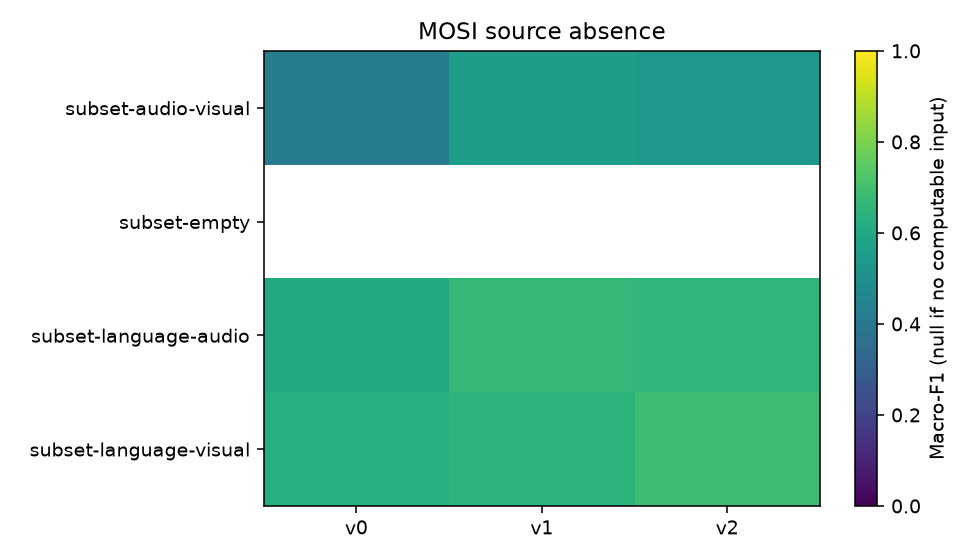

### Saved Figure: mosi-baselines
Clean frozen fusion, source-only and deterministic majority references.

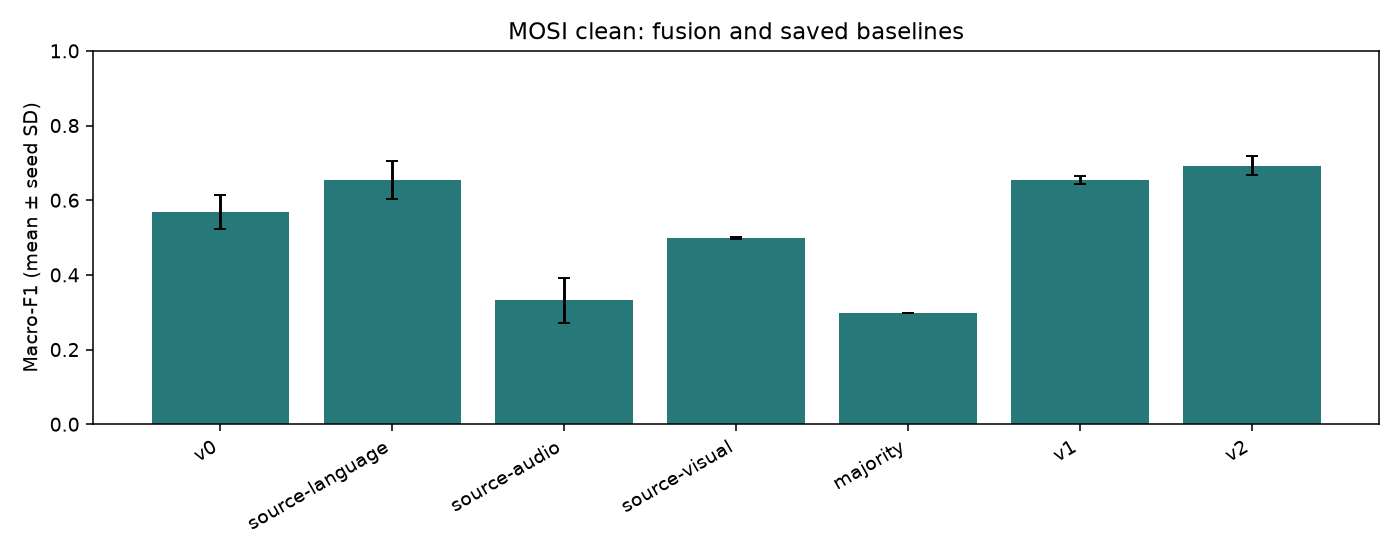

### Saved Figure: mosi-delay
Added reception delay / support; MOSI quality is undefined under offline closure.

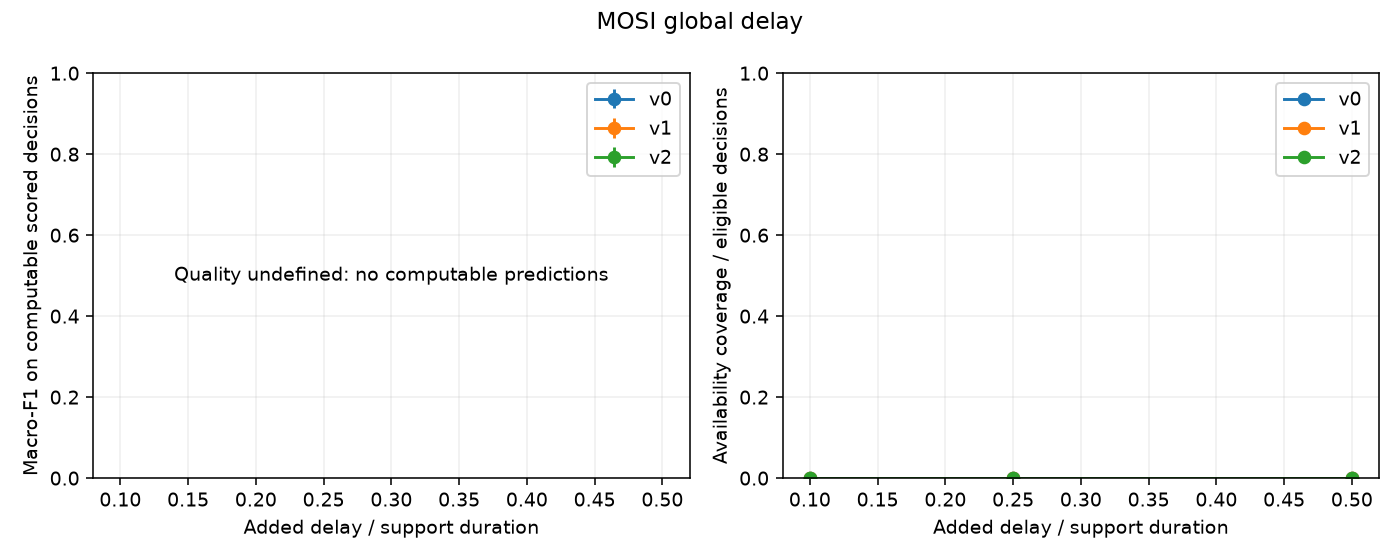

### Saved Figure: mosi-paired-bootstrap
Saved seed-conditional group-bootstrap intervals; descriptive, not significance.

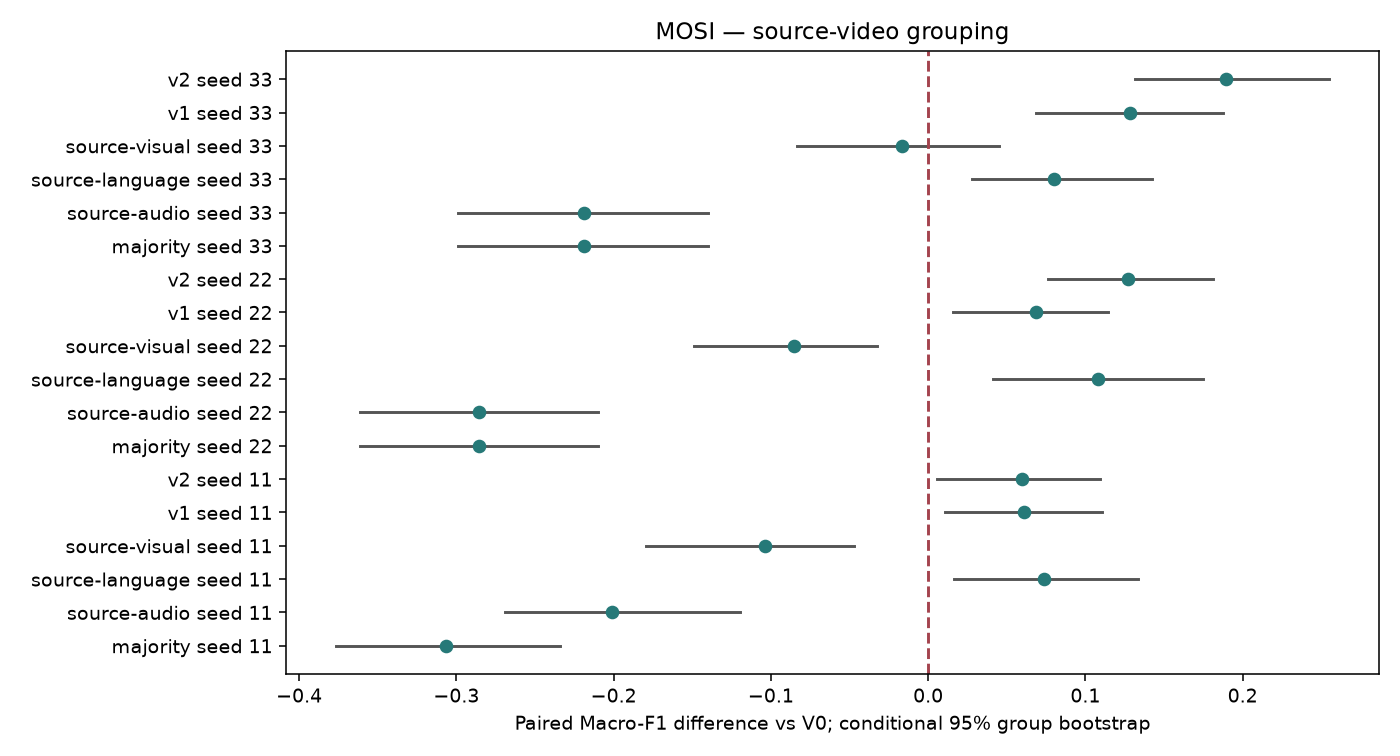

### Saved Figure: mosi-removal
Shared global independent observation removal schedules, 10/30/50%.

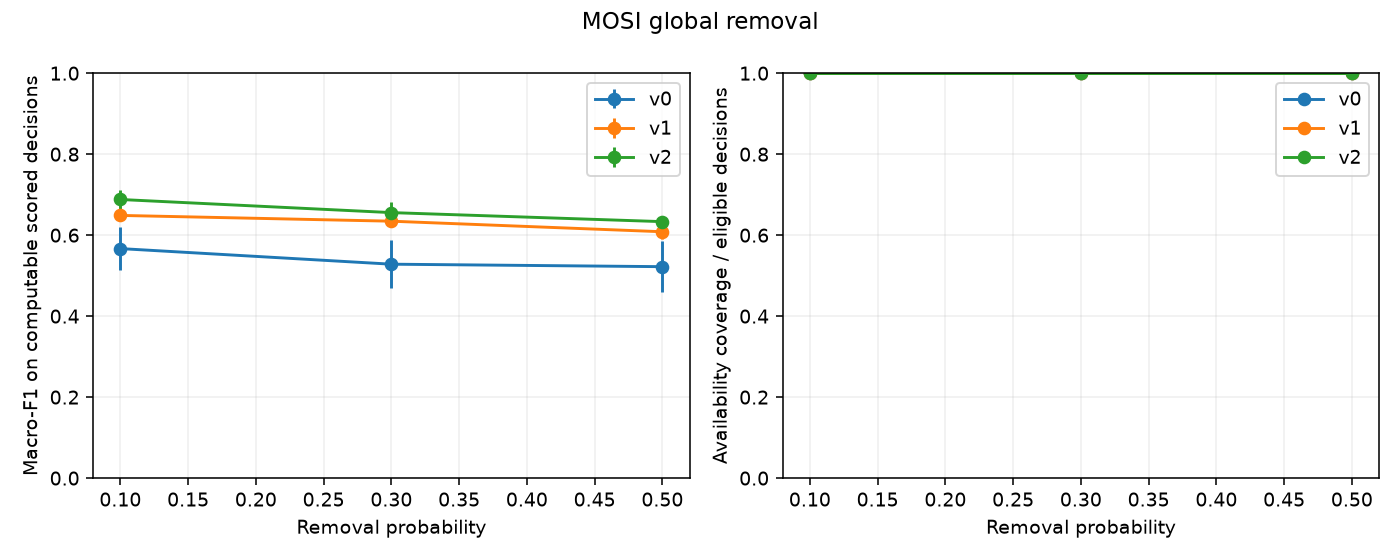

### Saved Figure: pamap2-absence
Empty and leave-one-source-out conditions; interpret quality together with availability.

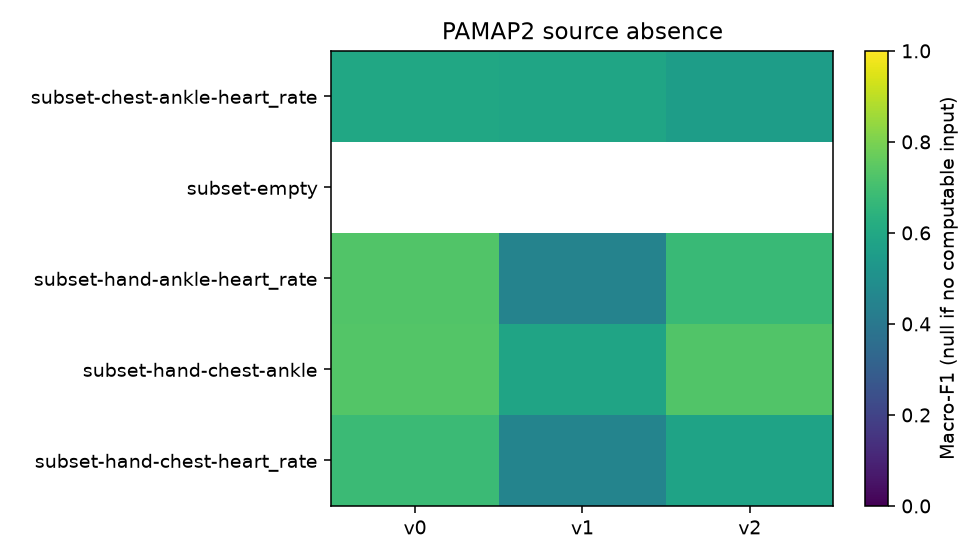

### Saved Figure: pamap2-baselines
Clean frozen fusion, source-only and deterministic majority references.

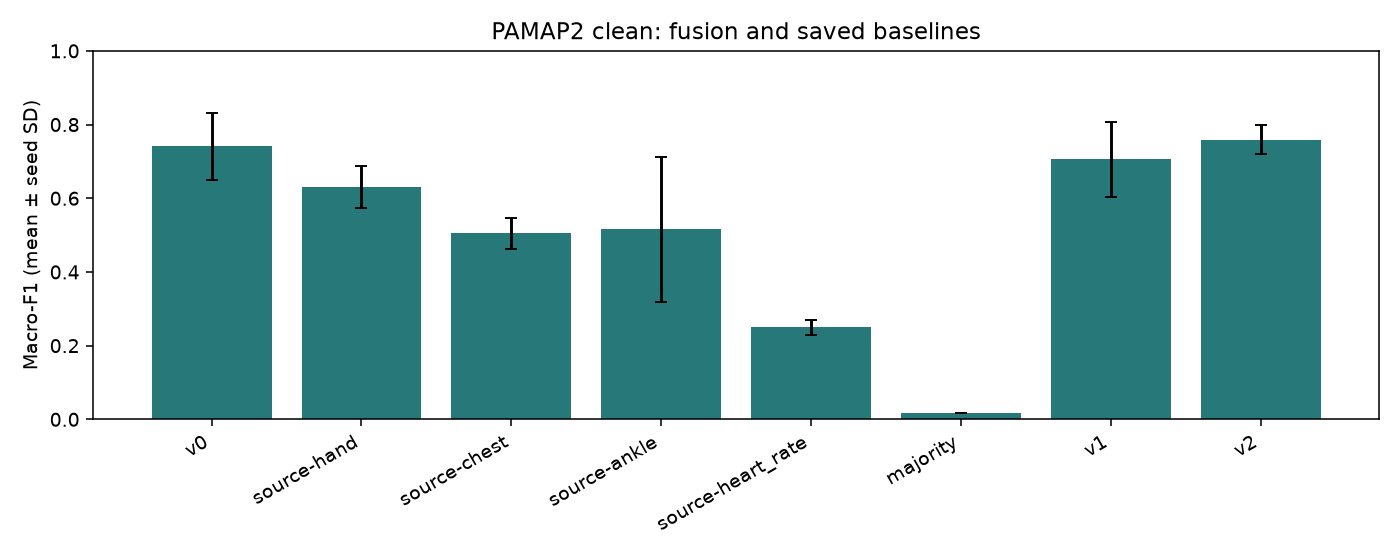

### Saved Figure: pamap2-delay
Added reception delay / support; MOSI quality is undefined under offline closure.

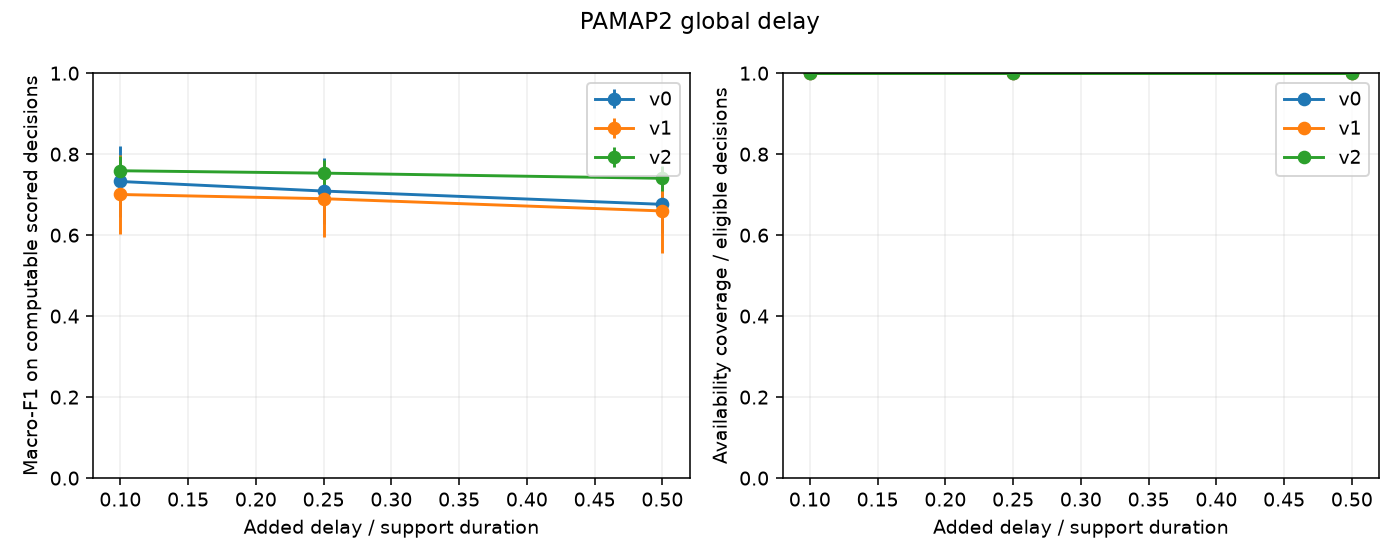

### Saved Figure: pamap2-paired-bootstrap
Saved seed-conditional group-bootstrap intervals; descriptive, not significance.

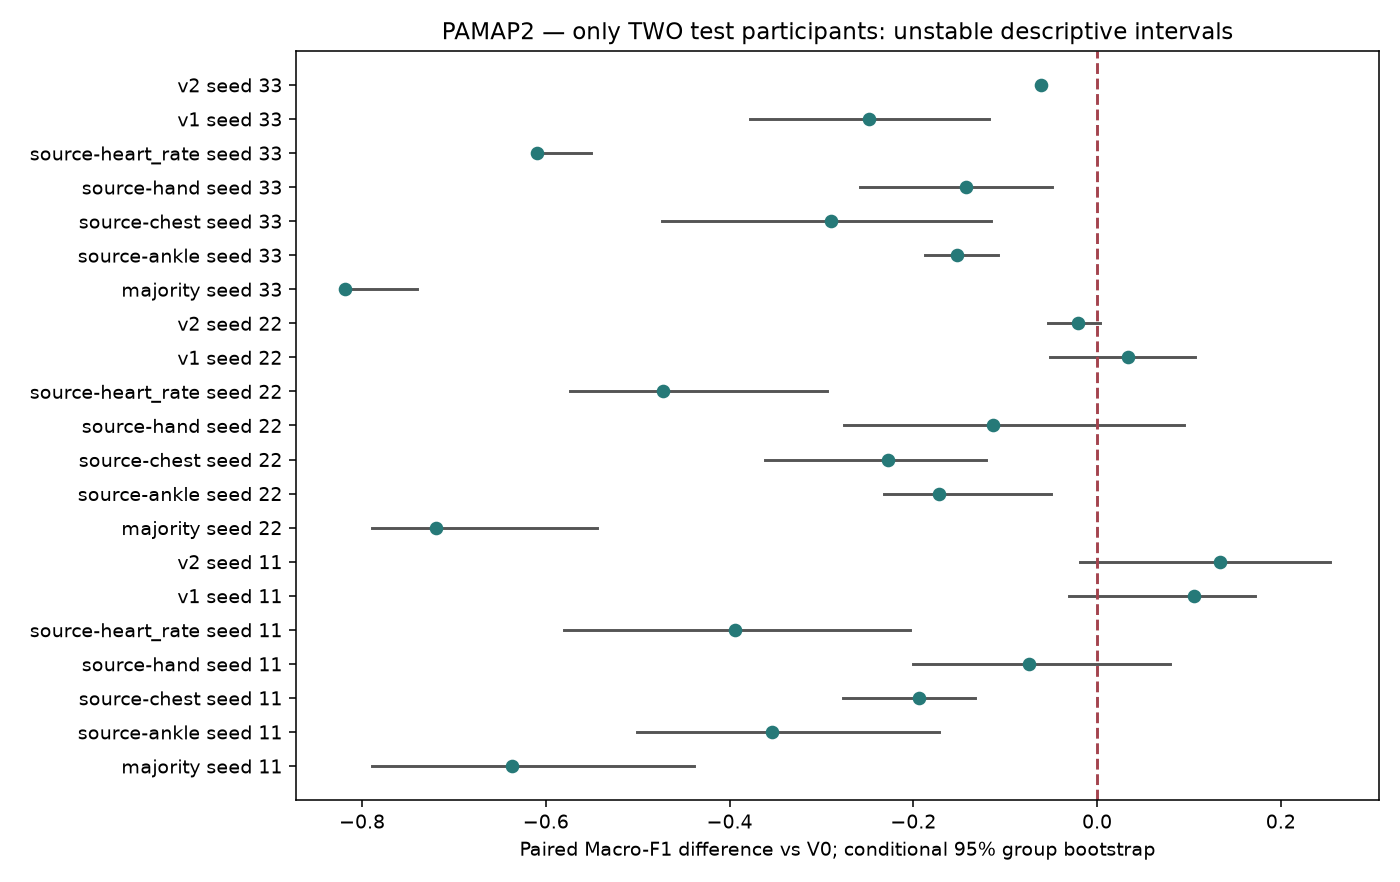

### Saved Figure: pamap2-removal
Shared global independent observation removal schedules, 10/30/50%.

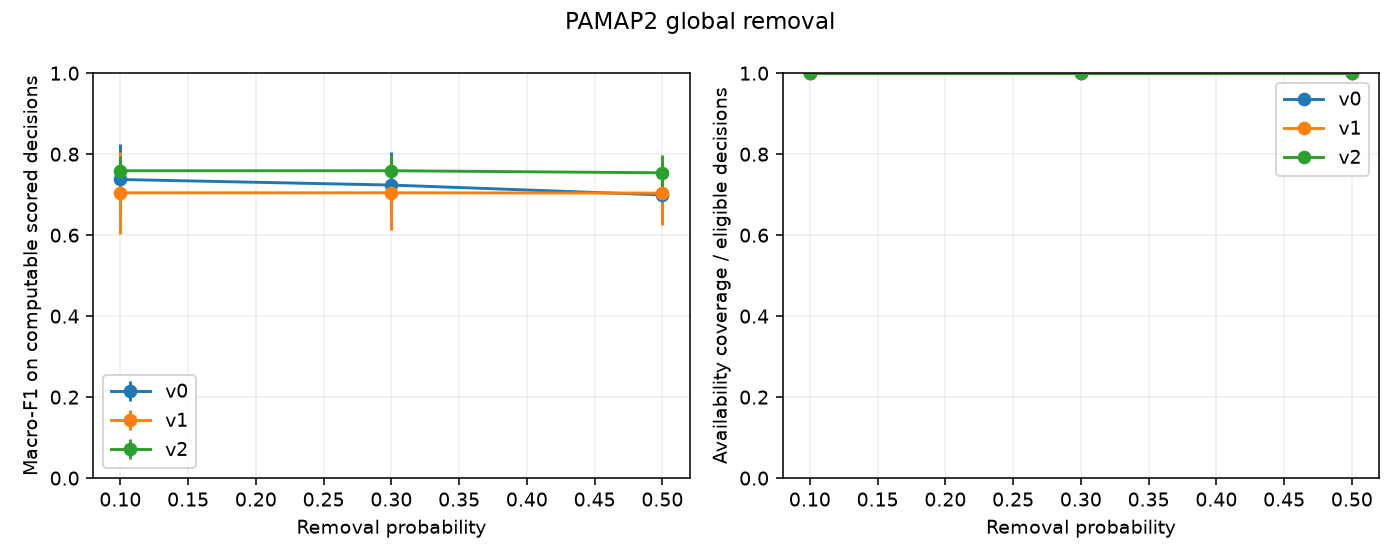

### Saved Figure: replay-latency
Whole-test replay prediction quantiles; measured concurrent workload, not an SLA.

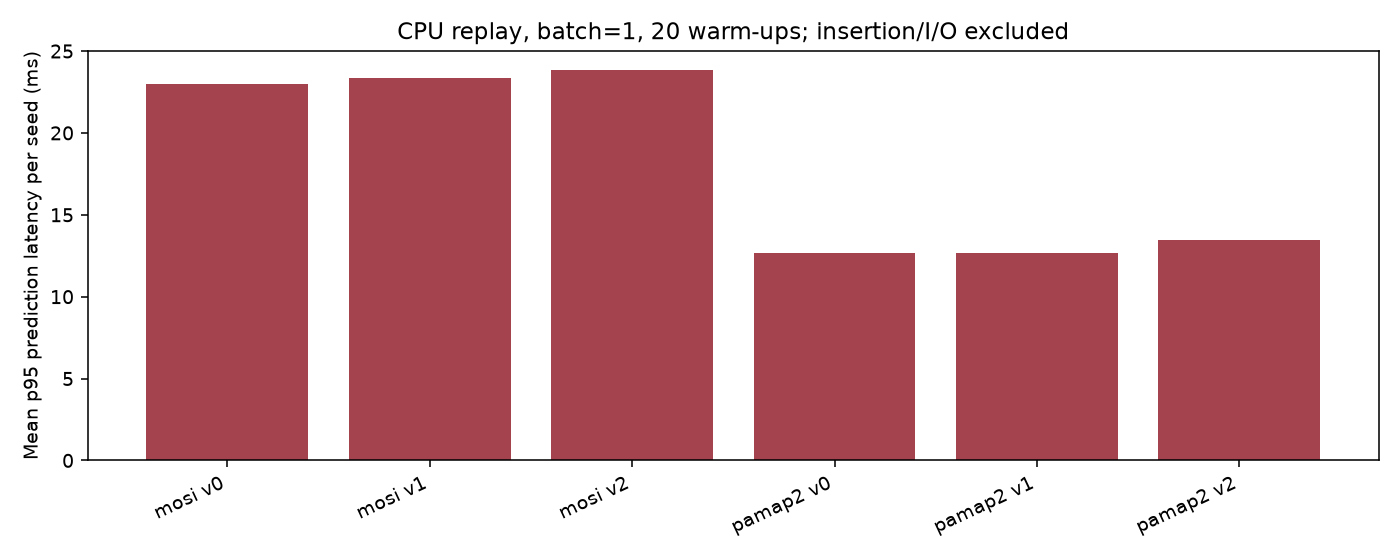

All 11 original figures embedded without modifying their source files. Clean extension Macro-F1 equals all 18 original test results exactly.


In [10]:
assert len(robust)==230 and robust.groupby('application').size().to_dict()=={'mosi':109,'pamap2':121}
fusion_robust = robust[robust.model.isin(MODELS)].copy()
assert len(fusion_robust)==207
mosi_delay = fusion_robust[fusion_robust.application.eq('mosi') & fusion_robust.kind.eq('delay')]
assert len(mosi_delay)==27 and mosi_delay.computable.eq(0).all() and mosi_delay.coverage.eq(0).all()
assert mosi_delay[['macro_f1','balanced_accuracy','nll','brier','ece']].isna().all().all()
assert fusion_robust[fusion_robust.scenario.eq('subset-empty')].macro_f1.isna().all()
TABLES['robustness_all_230'] = robust
show_complete(robust.sort_values(['application','scenario','model','seed']),'Every saved robustness and baseline evaluation; null means undefined')
robust_aggregates = fusion_robust.groupby(['application','scenario','kind','severity','model'],dropna=False).agg(seeds=('seed','size'),macro_f1_valid=('macro_f1','count'),macro_f1_mean=('macro_f1','mean'),macro_f1_seed_sd=('macro_f1','std'),balanced_accuracy_mean=('balanced_accuracy','mean'),balanced_accuracy_seed_sd=('balanced_accuracy','std'),coverage_mean=('coverage','mean'),coverage_seed_sd=('coverage','std'),nll_mean=('nll','mean'),brier_mean=('brier','mean'),ece_mean=('ece','mean')).reset_index()
assert len(robust_aggregates)==69 and robust_aggregates.seeds.eq(3).all()
TABLES['robustness_aggregates'] = robust_aggregates
show_complete(robust_aggregates,'All 69 fusion setting summaries; three nominal seeds per setting')
reference_clean = fusion_robust[fusion_robust.scenario.eq('clean')][['application','model','seed','macro_f1','balanced_accuracy','coverage']]
degradation = fusion_robust.merge(reference_clean,on=['application','model','seed'],suffixes=('','_clean'),validate='many_to_one')
for metric in ['macro_f1','balanced_accuracy','coverage']:
    degradation[f'{metric}_minus_clean'] = degradation[metric]-degradation[f'{metric}_clean']
TABLES['descriptive_scenario_deltas'] = degradation
saved_degradation = pd.read_csv(STUDY / 'degradation_deltas.csv')
TABLES['saved_degradation_deltas'] = saved_degradation
show_complete(degradation[['application','scenario','model','seed','computable','eligible','macro_f1_minus_clean','balanced_accuracy_minus_clean','coverage_minus_clean']],'All scenario-minus-clean fusion differences')
clean_check = reference_clean.merge(clean[clean.partition.eq('test')][['application','model','seed','macro_f1']],on=['application','model','seed'],suffixes=('_extension','_original'),validate='one_to_one')
assert (clean_check.macro_f1_extension-clean_check.macro_f1_original).abs().max()==0
TABLES['clean_non_regression'] = clean_check
saved_figures = sorted((STUDY / 'figures').glob('*.png'))
assert len(saved_figures)==11
figure_captions = {'absence':'Empty and leave-one-source-out conditions; interpret quality together with availability.','baselines':'Clean frozen fusion, source-only and deterministic majority references.','delay':'Added reception delay / support; MOSI quality is undefined under offline closure.','paired-bootstrap':'Saved seed-conditional group-bootstrap intervals; descriptive, not significance.','removal':'Shared global independent observation removal schedules, 10/30/50%.','latency':'Whole-test replay prediction quantiles; measured concurrent workload, not an SLA.'}
for image_path in saved_figures:
    caption_key = 'paired-bootstrap' if image_path.stem.endswith('paired-bootstrap') else image_path.stem.split('-')[-1]
    display(Markdown(f'### Saved Figure: {image_path.stem}\n{figure_captions[caption_key]}'))
    display(Image(data=image_path.read_bytes(),format='png'))
print('All 11 original figures embedded without modifying their source files. Clean extension Macro-F1 equals all 18 original test results exactly.')

### Recorded replay measurements

The 54 replays cover all 686 MOSI segments and 8,079 scheduled PAMAP2 decisions for nine model/seed combinations across three conditions, totaling 236,655 model-decision records. The final replay traces had zero parity failures. The 563 batch-size-32 score discrepancies were rechecked at batch size one with the original tolerance; strict equivalence at batch size 32 is not claimed.

Mean per-seed prediction p95 ranges from 22.974 to 23.819 ms on MOSI and 12.677 to 13.433 ms on PAMAP2. Including measured ingestion raises the corresponding clean means to 59.425-59.987 ms and 16.813-17.664 ms. These timings come from concurrent CPU workloads with one shared bounded input buffer; they are not end-to-end acquisition latency or an SLA. Process RSS is cumulative, so it cannot be assigned to an individual model.

### All 54 replay measurements, actual total-latency quantiles and scope fields (54 rows)

application,arrivals,batch_size,buffer_high_water_bytes,buffer_max_rows,decisions,expired_arrivals,insertion_p50_ms,insertion_p95_ms,memory_method,model,parity_failures,prediction_p50_ms,prediction_p95_ms,process_peak_rss_bytes,scenario,schedule_hash,seed,sequences,threads,timing_scope,warmup_calls,batch32_numerical_rechecks,max_batch32_score_error_rechecked,parity_method,run_id,timed_decisions,ingestion_prediction_p50_ms,ingestion_prediction_p95_ms
mosi,448359,1,1926155,4380,686,0,12.311875,36.348749,"process lifetime peak RSS, cumulative; shared buffer for nine frozen predictors",v0,0,7.800146,22.865958,951549952,clean,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,11,686,4,selection/normalize/collate/model/postprocessing; insertion and trace writing separate,20,null,null,null,clean-long-20261027-run1-mosi-v0-seed-11,686,19.829687,60.401344
mosi,448359,1,1926155,4380,686,0,12.311875,36.348749,"process lifetime peak RSS, cumulative; shared buffer for nine frozen predictors",v0,0,7.735542,23.058687,951549952,clean,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,22,686,4,selection/normalize/collate/model/postprocessing; insertion and trace writing separate,20,null,null,null,clean-long-20261027-run1-mosi-v0-seed-22,686,19.750479,59.622646
mosi,448359,1,1926155,4380,686,0,12.311875,36.348749,"process lifetime peak RSS, cumulative; shared buffer for nine frozen predictors",v0,0,7.711438,22.997583,951549952,clean,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,33,686,4,selection/normalize/collate/model/postprocessing; insertion and trace writing separate,20,null,null,null,clean-long-20261027-run1-mosi-v0-seed-33,686,19.689272,59.319936
mosi,448359,1,1926155,4380,686,0,12.311875,36.348749,"process lifetime peak RSS, cumulative; shared buffer for nine frozen predictors",v1,0,7.652292,23.225812,951549952,clean,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,11,686,4,selection/normalize/collate/model/postprocessing; insertion and trace writing separate,20,null,null,null,clean-long-20261027-run1-mosi-v1-seed-11,686,19.714791,59.326282
mosi,448359,1,1926155,4380,686,0,12.311875,36.348749,"process lifetime peak RSS, cumulative; shared buffer for nine frozen predictors",v1,0,7.630166,23.640177,951549952,clean,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,22,686,4,selection/normalize/collate/model/postprocessing; insertion and trace writing separate,20,null,null,null,clean-long-20261027-run1-mosi-v1-seed-22,686,19.629833,59.430667
mosi,448359,1,1926155,4380,686,0,12.311875,36.348749,"process lifetime peak RSS, cumulative; shared buffer for nine frozen predictors",v1,0,7.695000,23.155666,951549952,clean,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,33,686,4,selection/normalize/collate/model/postprocessing; insertion and trace writing separate,20,null,null,null,clean-long-20261027-run1-mosi-v1-seed-33,686,19.799520,59.516979
mosi,448359,1,1926155,4380,686,0,12.311875,36.348749,"process lifetime peak RSS, cumulative; shared buffer for nine frozen predictors",v2,0,8.106938,23.791562,951549952,clean,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,11,686,4,selection/normalize/collate/model/postprocessing; insertion and trace writing separate,20,null,null,null,clean-long-20261027-run1-mosi-v2-seed-11,686,20.260479,59.765146
mosi,448359,1,1926155,4380,686,0,12.311875,36.348749,"process lifetime peak RSS, cumulative; shared buffer for nine frozen predictors",v2,0,8.193042,23.539782,951549952,clean,de5a30f261935244a828fafac4c2ac11f6c16034229343a4b3adf7a76f7b6ff3,22,686,4,selection/normalize/collate/model/postprocessing; insertion and trace writing separate,20,null,null,null,clean-long-20261027-run1-mosi-v2-seed-22,686,20.289354,60.329584
mosi,448359,1,1926155,4380,686,0,12.311875,36.348749,"process lifetime peak RSS, cumulative; shared buffer for nine frozen predictors",v2,0,8.082854,24.127084,951549952,clean,de5a30f261935244a82

### Means of per-seed quantiles, not pooled quantiles; shared cumulative memory (18 rows)

application,scenario,model,seeds,decisions_each,prediction_p50_mean_ms,prediction_p95_mean_ms,prediction_p95_seed_sd_ms,actual_total_p50_mean_ms,actual_total_p95_mean_ms,actual_total_p95_seed_sd_ms,max_cumulative_process_rss_bytes,max_shared_buffer_estimate_bytes,batch32_rechecks,parity_failures
mosi,clean,v0,3,686,7.749042,22.974076,0.098491,19.756479,59.781309,0.557890,951549952,1926155,0.0,0
mosi,clean,v1,3,686,7.659153,23.340552,0.261842,19.714715,59.424642,0.095491,951549952,1926155,0.0,0
mosi,clean,v2,3,686,8.127611,23.819476,0.294644,20.292291,59.986684,0.301154,951549952,1926155,0.0,0
mosi,delay-language-audio-visual-0.25,v0,3,686,0.021639,0.029702,0.001676,0.021798,0.029979,0.001747,1016872960,0,0.0,0
mosi,delay-language-audio-visual-0.25,v1,3,686,0.020527,0.028198,0.000530,0.020667,0.028503,0.000582,1016872960,0,0.0,0
mosi,delay-language-audio-visual-0.25,v2,3,686,0.020327,0.027174,0.000247,0.020473,0.027309,0.000239,1016872960,0,0.0,0
mosi,removal-language-audio-visual-0.3,v0,3,686,5.646195,16.769820,0.506806,14.428841,42.996316,0.780860,921632768,1367114,0.0,0
mosi,removal-language-audio-visual-0.3,v1,3,686,5.585264,16.837333,0.592142,14.415667,43.241392,0.862301,921632768,1367114,0.0,0
mosi,removal-language-audio-visual-0.3,v2,3,686,5.997465,17.228497,0.230956,14.582549,43.272663,0.365576,921632768,1367114,1.0,0
pamap2,clean,v0,3,8079,11.765209,12.696802,0.083799,15.528625,16.864528,0.092002,918224896,287879,1.0,0


### Recorded parity and memory summary (7 rows)

check,saved_value
Final replay rows,5.400000e+01
Model/decision records,2.366550e+05
Final parity failures,0.000000e+00
Batch32 numerical rechecks,5.630000e+02
Max batch32 score error rechecked,2.026402e-05
Max cumulative process peak RSS (decimal GB),1.281737e+00
Max shared buffer estimate (bytes),1.926155e+06


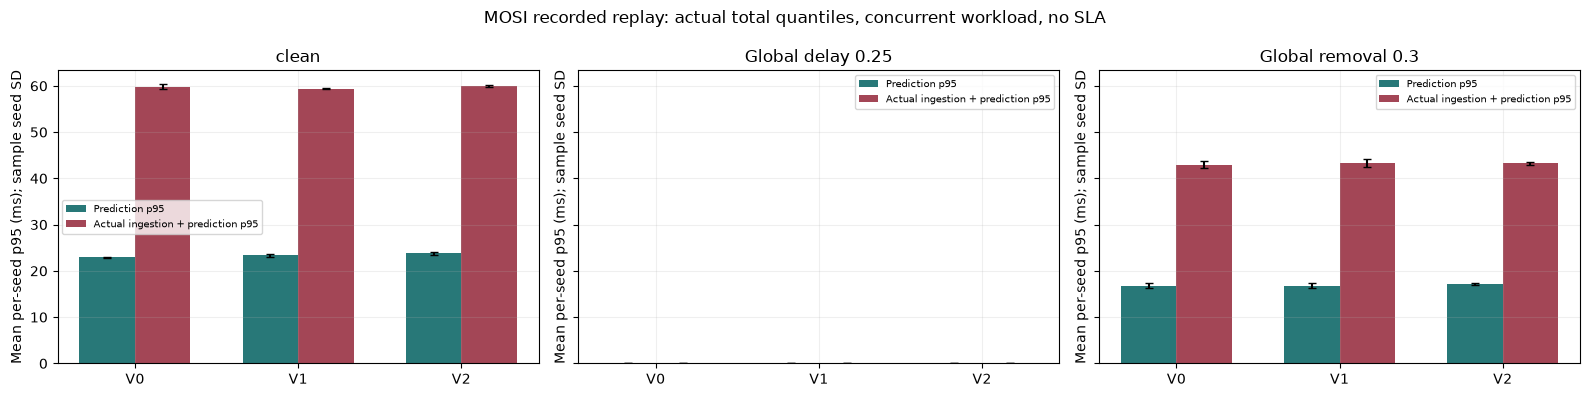

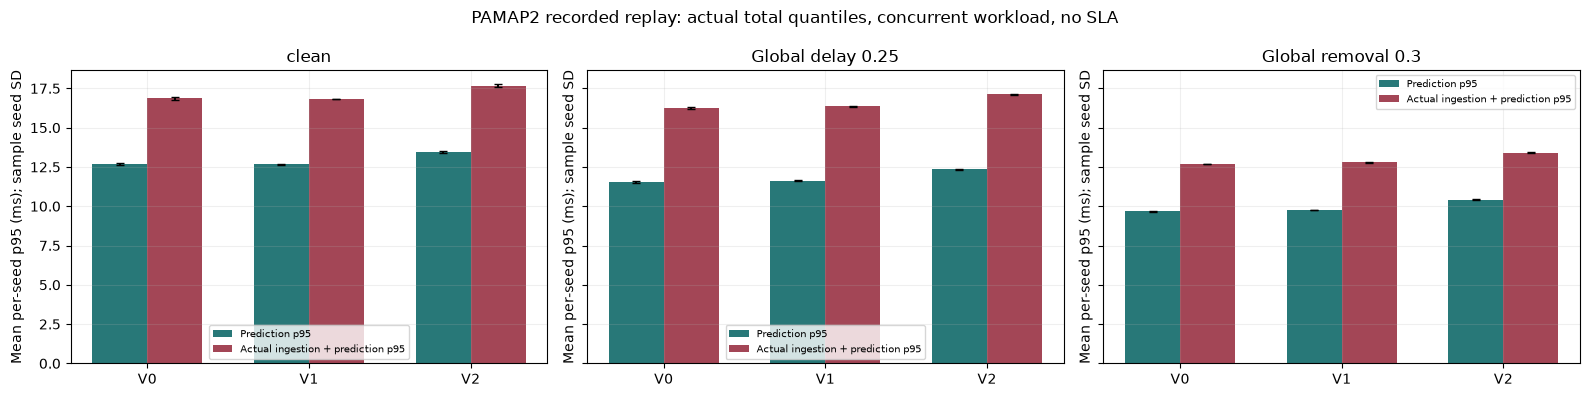

In [11]:
assert len(replay)==54 and len(total_latency)==54
assert not replay.duplicated(['application','scenario','model','seed']).any()
assert replay.parity_failures.eq(0).all()
assert replay.batch_size.eq(1).all() and replay.threads.eq(4).all() and replay.warmup_calls.eq(20).all()
assert int(replay.decisions.sum())==236655
assert int(replay.batch32_numerical_rechecks.fillna(0).sum())==563
replay_report = replay.merge(run_metadata[['application','model','seed','run_id']],on=['application','model','seed'],validate='many_to_one').merge(total_latency,on=['application','scenario','run_id'],validate='one_to_one')
assert len(replay_report)==54 and replay_report.timed_decisions.eq(replay_report.decisions).all()
TABLES['replay_all_54'] = replay_report
TABLES['replay_total_latency'] = total_latency
show_complete(replay_report,'All 54 replay measurements, actual total-latency quantiles and scope fields')
replay_aggregates = replay_report.groupby(['application','scenario','model']).agg(seeds=('seed','size'),decisions_each=('decisions','first'),prediction_p50_mean_ms=('prediction_p50_ms','mean'),prediction_p95_mean_ms=('prediction_p95_ms','mean'),prediction_p95_seed_sd_ms=('prediction_p95_ms','std'),actual_total_p50_mean_ms=('ingestion_prediction_p50_ms','mean'),actual_total_p95_mean_ms=('ingestion_prediction_p95_ms','mean'),actual_total_p95_seed_sd_ms=('ingestion_prediction_p95_ms','std'),max_cumulative_process_rss_bytes=('process_peak_rss_bytes','max'),max_shared_buffer_estimate_bytes=('buffer_high_water_bytes','max'),batch32_rechecks=('batch32_numerical_rechecks','sum'),parity_failures=('parity_failures','sum')).reset_index()
TABLES['replay_aggregates'] = replay_aggregates
show_complete(replay_aggregates,'Means of per-seed quantiles, not pooled quantiles; shared cumulative memory')
replay_checks = pd.DataFrame({'check':['Final replay rows','Model/decision records','Final parity failures','Batch32 numerical rechecks','Max batch32 score error rechecked','Max cumulative process peak RSS (decimal GB)','Max shared buffer estimate (bytes)'],'saved_value':[len(replay),int(replay.decisions.sum()),int(replay.parity_failures.sum()),int(replay.batch32_numerical_rechecks.fillna(0).sum()),float(replay.max_batch32_score_error_rechecked.max()),float(replay.process_peak_rss_bytes.max()/1e9),int(replay.buffer_high_water_bytes.max())]})
TABLES['replay_checks'] = replay_checks
show_complete(replay_checks,'Recorded parity and memory summary')
for application in APPLICATIONS:
    scenarios = list(replay_aggregates[replay_aggregates.application.eq(application)].scenario.unique())
    figure, plot_axes = plt.subplots(1,len(scenarios),figsize=(16,4),sharey=True)
    for axis, scenario in zip(plot_axes,scenarios):
        rows = replay_aggregates[(replay_aggregates.application==application)&(replay_aggregates.scenario==scenario)].set_index('model').loc[MODELS]
        axis.bar(np.arange(3)-0.17,rows.prediction_p95_mean_ms,width=0.34,yerr=rows.prediction_p95_seed_sd_ms,capsize=3,label='Prediction p95',color='#287878')
        axis.bar(np.arange(3)+0.17,rows.actual_total_p95_mean_ms,width=0.34,yerr=rows.actual_total_p95_seed_sd_ms,capsize=3,label='Actual ingestion + prediction p95',color='#a34656')
        condition = 'clean' if scenario=='clean' else 'Global removal 0.3' if scenario.startswith('removal') else 'Global delay 0.25'
        axis.set_title(condition); axis.set_xticks(range(3),[model.upper() for model in MODELS]); axis.set_ylabel('Mean per-seed p95 (ms); sample seed SD'); axis.legend(fontsize=7)
    figure.suptitle(f'{application.upper()} recorded replay: actual total quantiles, concurrent workload, no SLA')
    figure.tight_layout(); FIGURES[f'{application}_replay_actual_totals']=figure; plt.show()

### Per-class results

MOSI V0's pooled negative recall is 0.3448, compared with 0.9134 for positive sentiment. V2 narrows that gap: 0.6728 negative and 0.7280 positive recall. These counts sum predictions from three seeds on the same videos; they complement, rather than replace, the per-seed scores above.

The PAMAP2 class tables show that performance varies across activities and seeds. Under conditions with no computable predictions, class quality remains undefined. The heatmaps therefore help locate where aggregate Macro-F1 conceals uneven class-level behavior.

### Saved class-map order: MOSI sign and PAMAP2 activity IDs (14 rows)

application,original_label,class_index
mosi,-1,0
mosi,1,1
pamap2,1,0
pamap2,2,1
pamap2,3,2
pamap2,4,3
pamap2,5,4
pamap2,6,5
pamap2,7,6
pamap2,12,7


### MOSI all clean class metrics, every seed and partition (36 rows)

class_index,precision,recall,f1,support,application,model,seed,partition
0,0.636364,0.325581,0.430769,43,mosi,v0,11,validation
1,0.674157,0.882353,0.764331,68,mosi,v0,11,validation
0,0.815385,0.419525,0.554007,379,mosi,v0,11,test
1,0.522777,0.870036,0.653117,277,mosi,v0,11,test
0,0.800000,0.279070,0.413793,43,mosi,v0,22,validation
1,0.677083,0.955882,0.792683,68,mosi,v0,22,validation
0,0.838323,0.369393,0.512821,379,mosi,v0,22,test
1,0.511247,0.902527,0.652742,277,mosi,v0,22,test
0,0.857143,0.139535,0.240000,43,mosi,v0,33,validation
1,0.644231,0.985294,0.779070,68,mosi,v0,33,validation


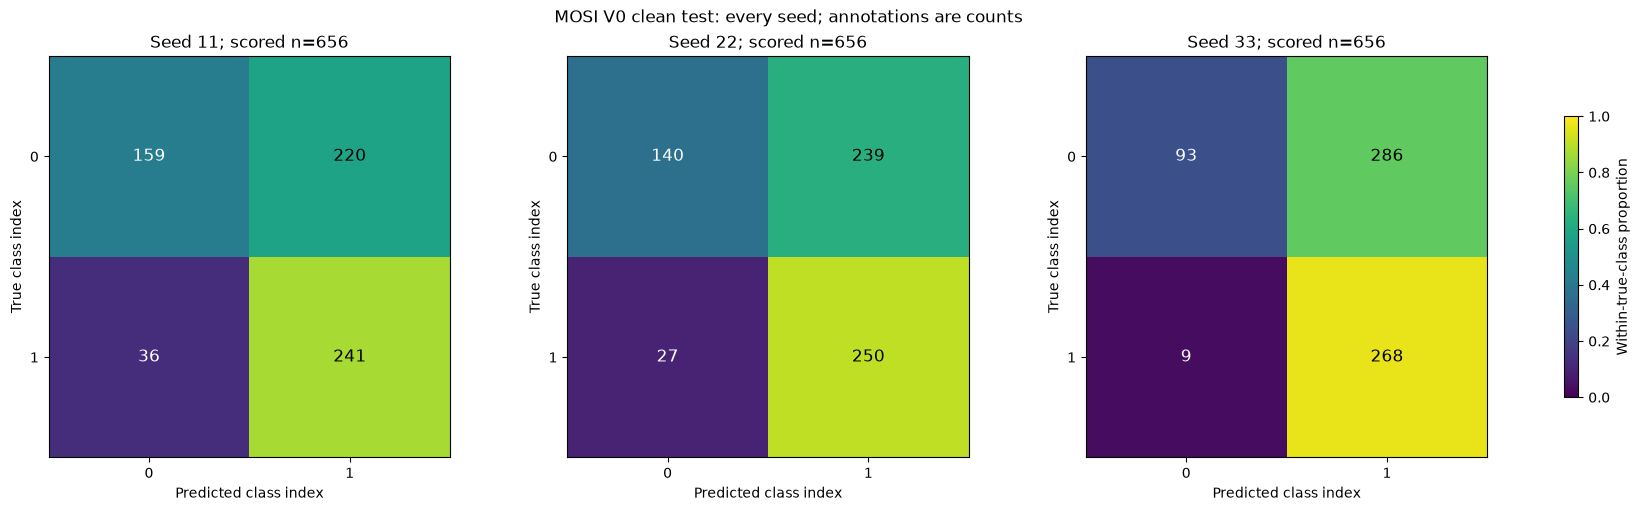

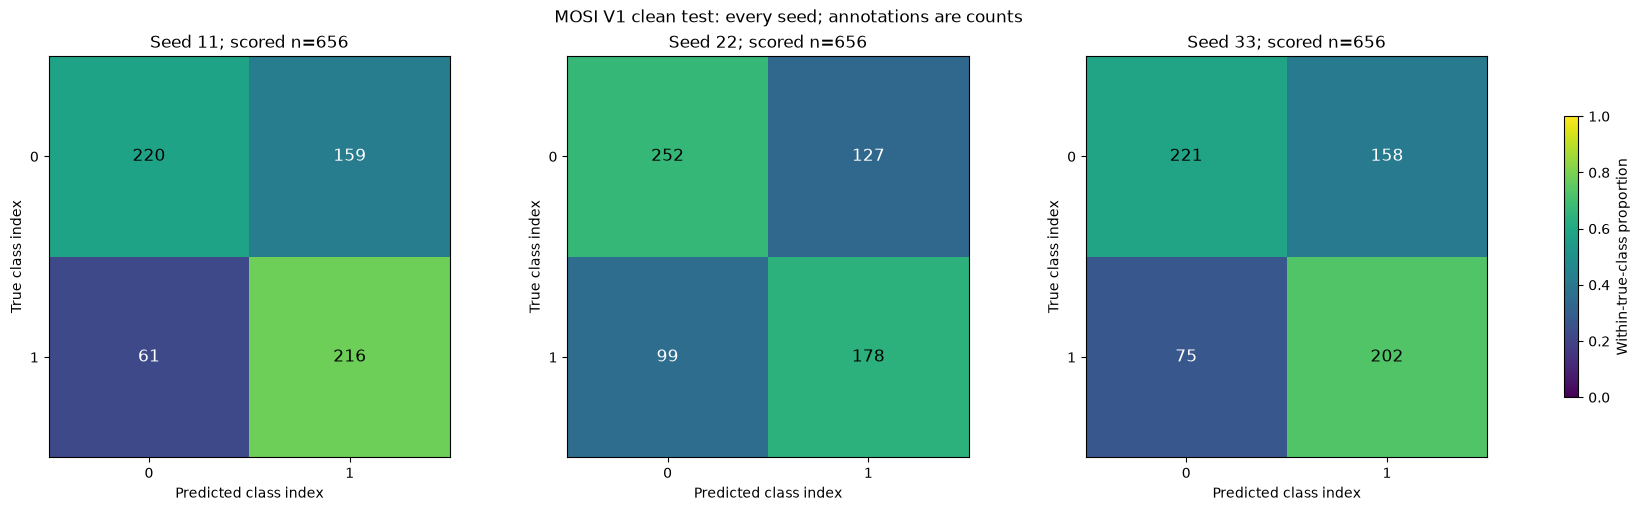

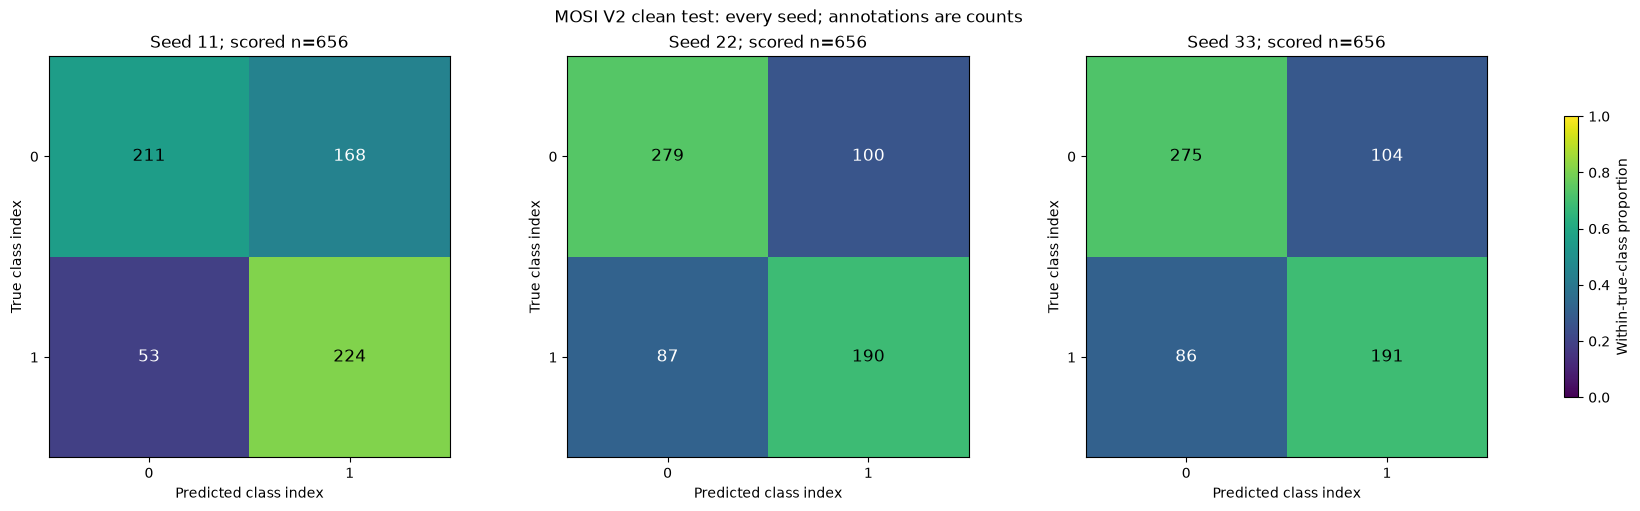

### PAMAP2 all clean class metrics, every seed and partition (216 rows)

class_index,precision,recall,f1,support,application,model,seed,partition
0,0.887265,0.844930,0.865580,503,pamap2,v0,11,validation
1,0.487252,0.351738,0.408551,489,pamap2,v0,11,validation
2,0.555228,0.810753,0.659091,465,pamap2,v0,11,validation
3,0.750746,0.928044,0.830033,542,pamap2,v0,11,validation
4,0.602446,0.924883,0.729630,213,pamap2,v0,11,validation
5,0.671212,0.956803,0.788958,463,pamap2,v0,11,validation
6,0.929032,0.300626,0.454259,479,pamap2,v0,11,validation
7,0.493766,0.605505,0.543956,327,pamap2,v0,11,validation
8,0.958974,0.642612,0.769547,291,pamap2,v0,11,validation
9,0.903226,0.846512,0.873950,430,pamap2,v0,11,validation


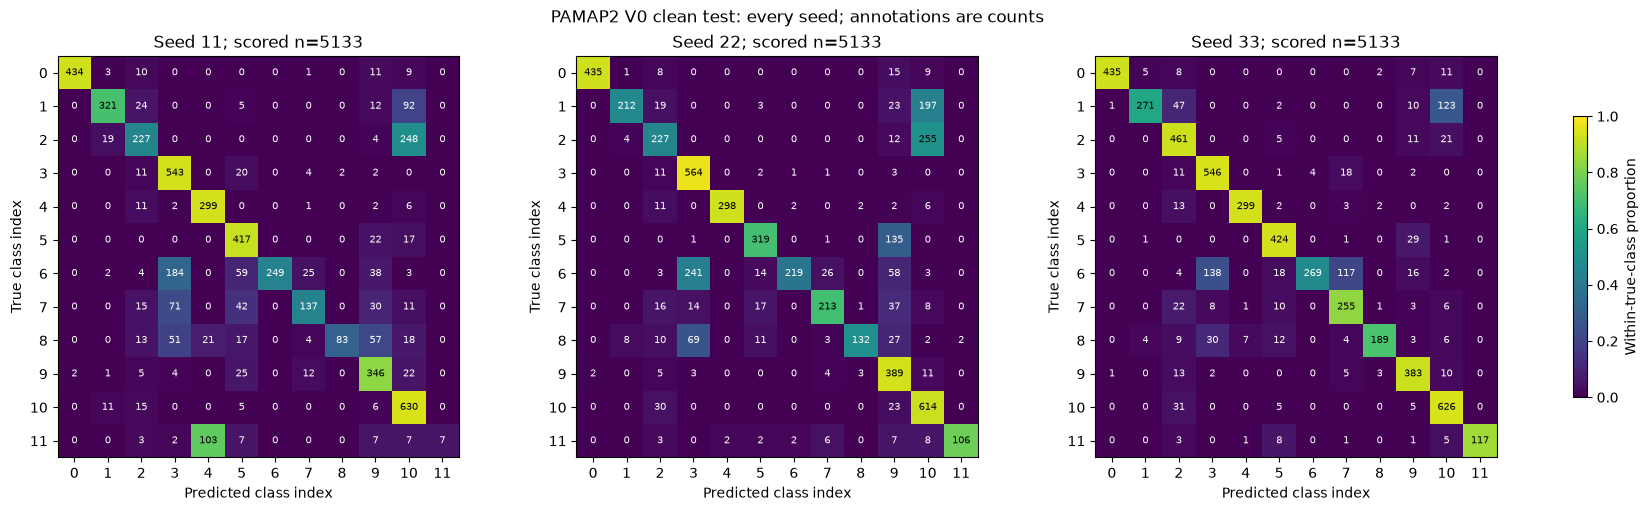

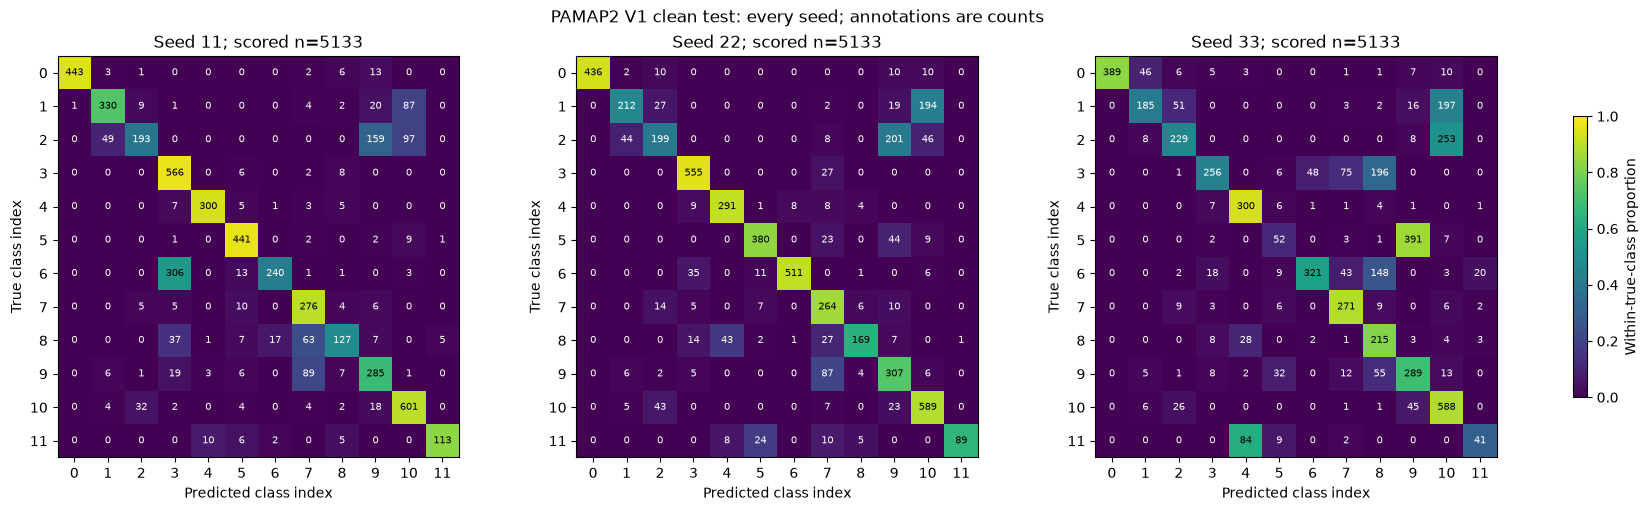

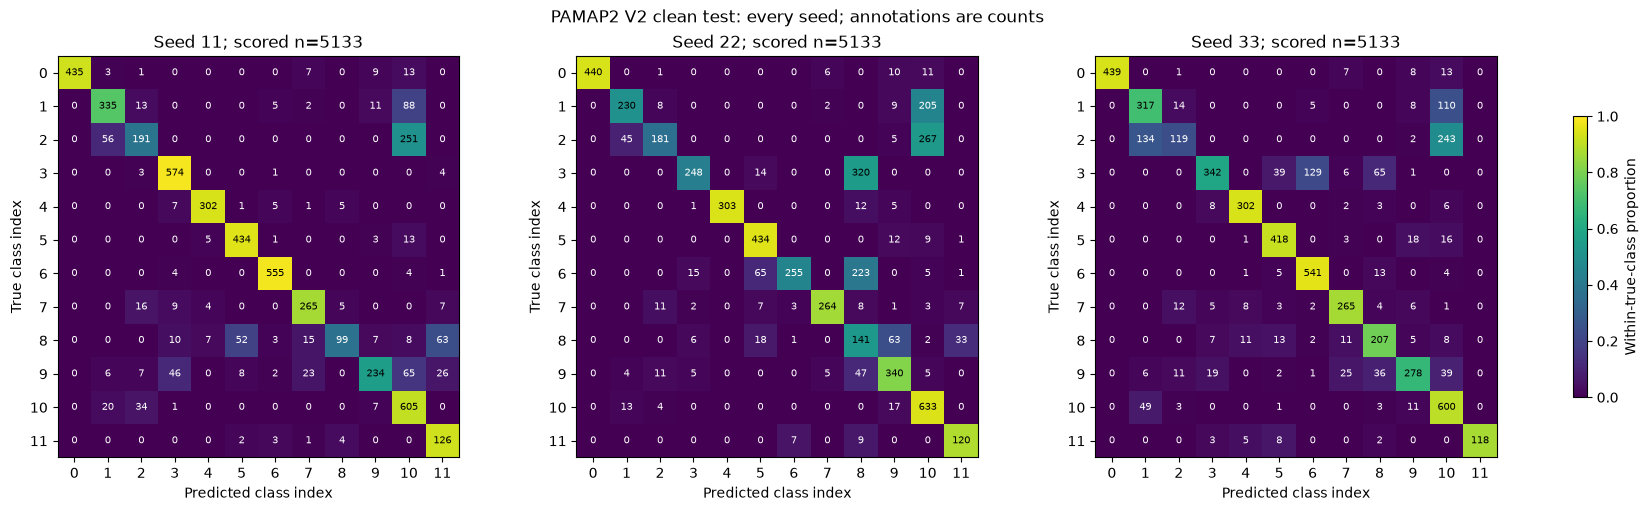

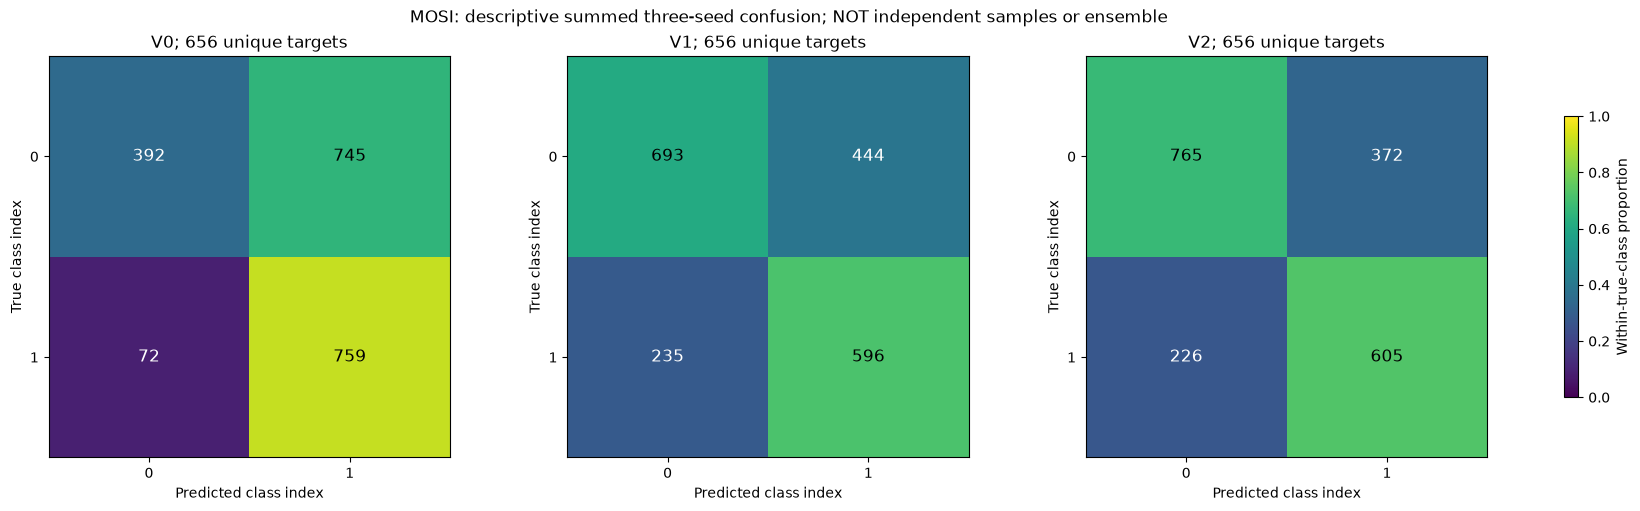

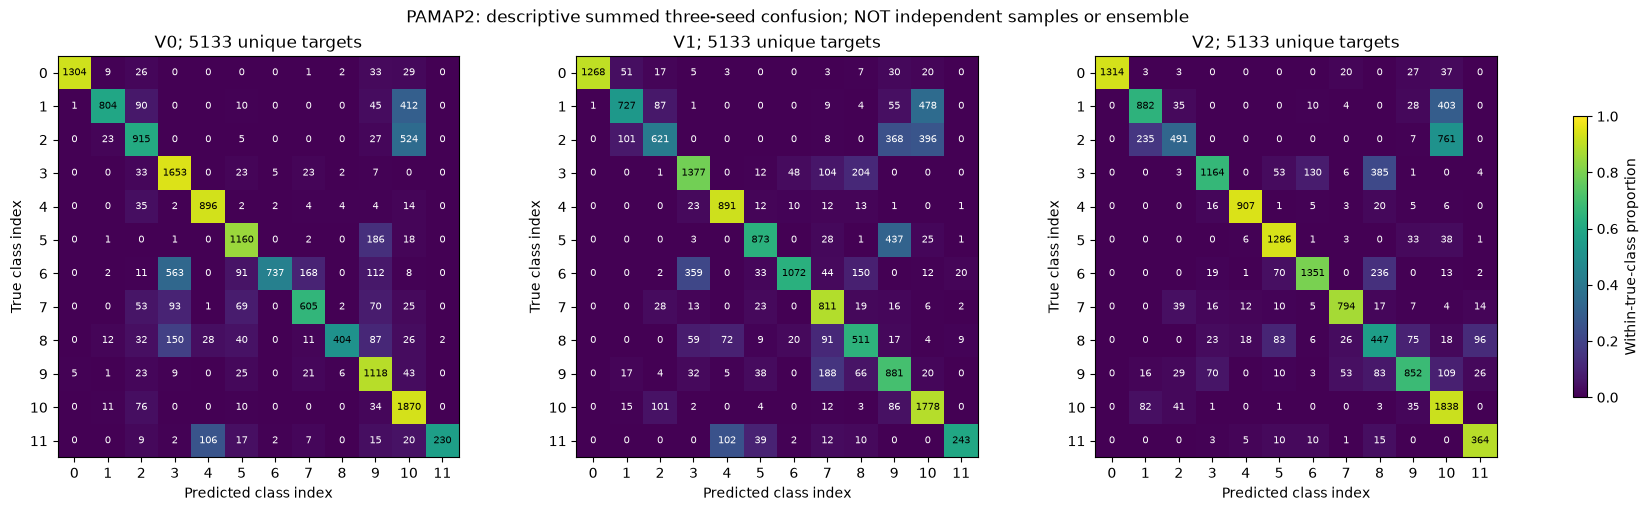

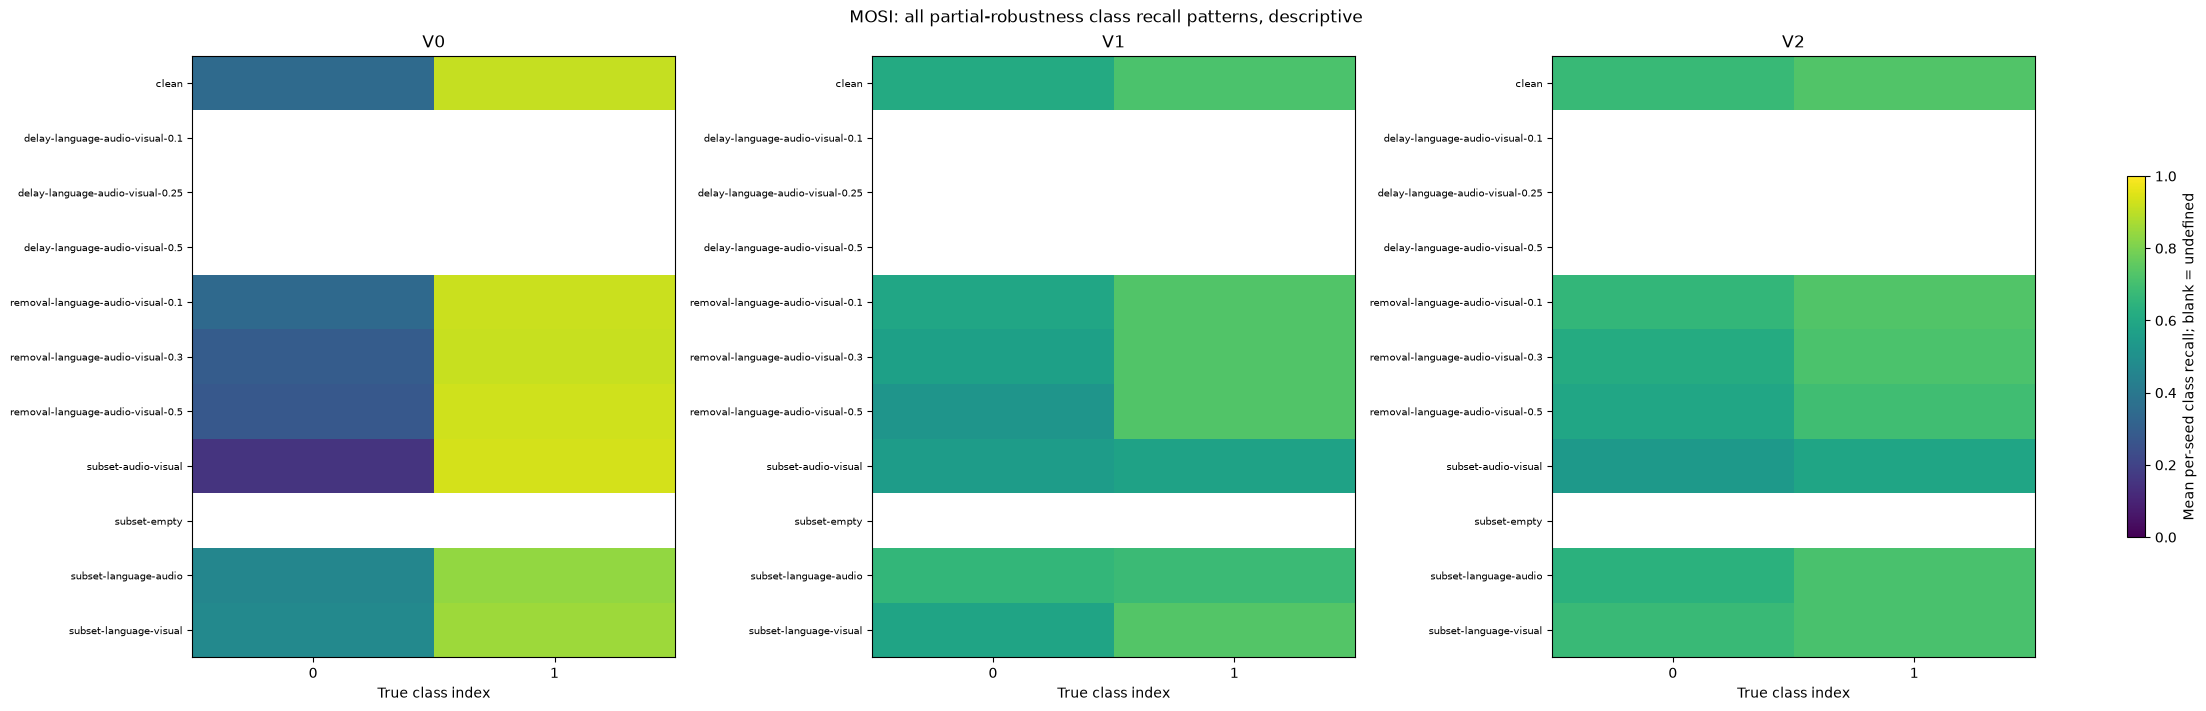

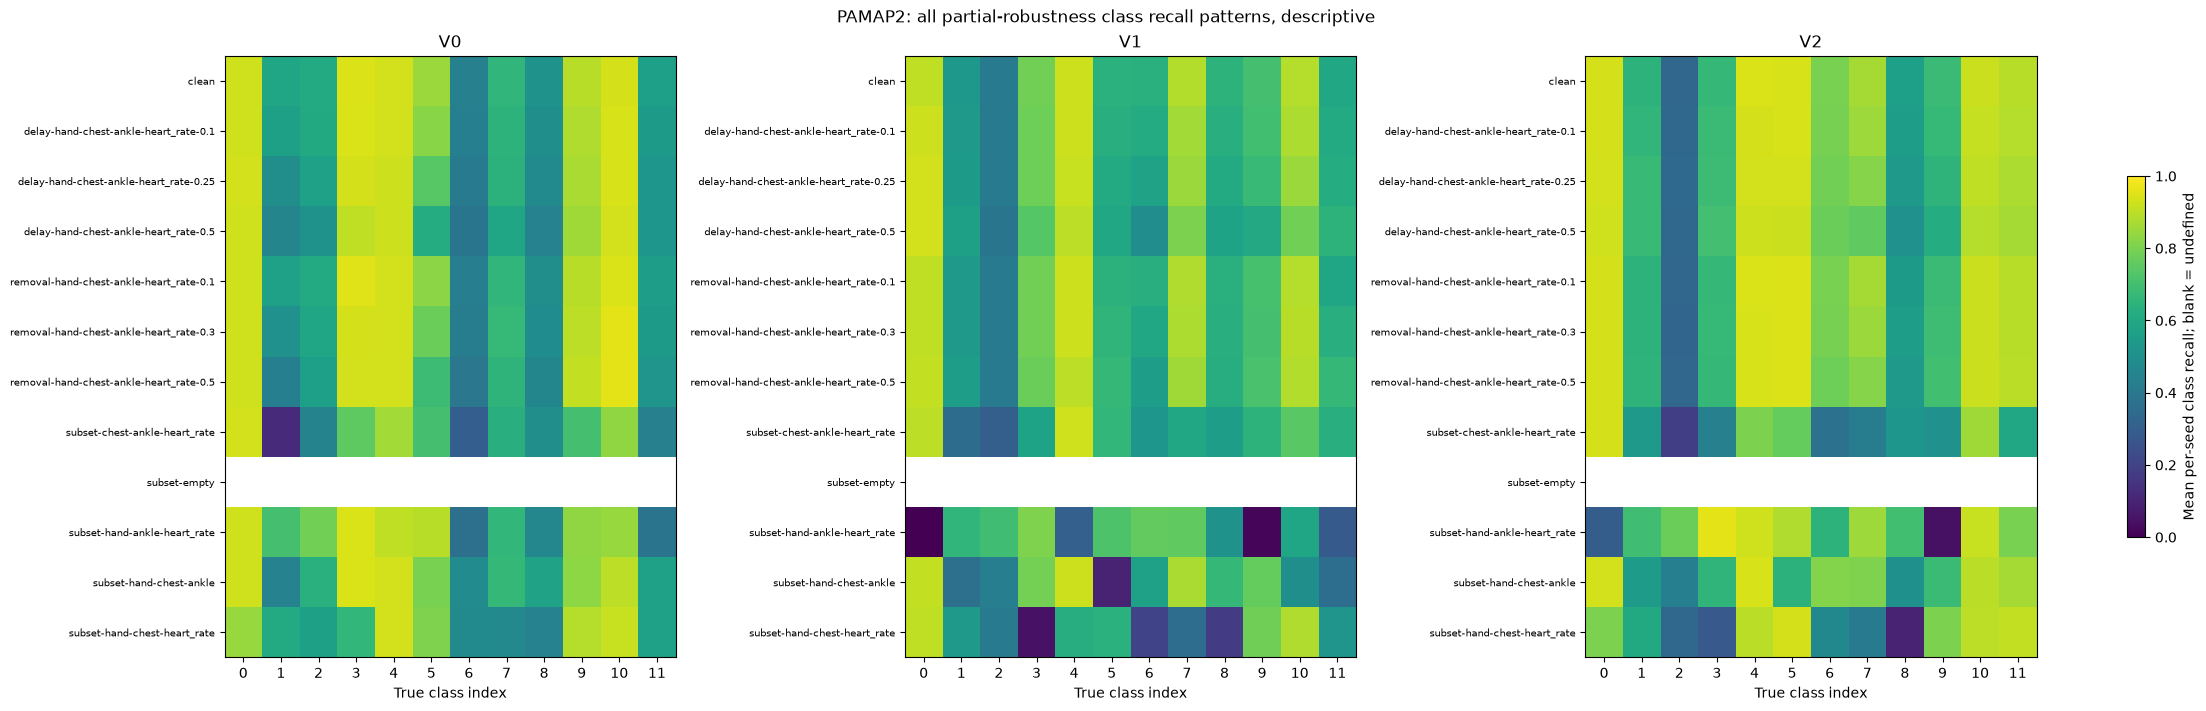

Verified 36 clean confusion matrices against saved labels, 252 clean class rows and all 230 final robustness confusion statuses.


In [12]:
from sklearn.metrics import confusion_matrix
class_maps = {application:read_json(prepared_roots[application] / 'manifest.json')['class_map'] for application in APPLICATIONS}
class_mapping = pd.DataFrame([{'application':application,'original_label':original_label,'class_index':class_index} for application,mapping in class_maps.items() for original_label,class_index in mapping.items()]).sort_values(['application','class_index'])
TABLES['class_mapping'] = class_mapping
show_complete(class_mapping,'Saved class-map order: MOSI sign and PAMAP2 activity IDs')
clean_class_frames = []
clean_confusions = {}
confusion_records = []
for entry in plan['entries']:
    application, model, seed = entry['application'],entry['model'],entry['seed']
    class_count = len(class_maps[application])
    for partition in ['validation','test']:
        directory = CLEAN / 'results' / entry['run_id'] / partition
        saved_matrix = pd.read_csv(directory / 'confusion.csv').to_numpy(dtype=int)
        selected = prediction_frames[(application,model,seed,partition)]
        selected = selected[selected.score_eligible & selected.computable]
        reconstructed = confusion_matrix(selected.target_class.astype(int),selected.predicted_class.astype(int),labels=list(range(class_count)))
        assert np.array_equal(saved_matrix,reconstructed) and int(saved_matrix.sum())==len(selected)
        clean_confusions[(application,model,seed,partition)] = saved_matrix
        clean_class_frames.append(pd.read_csv(directory / 'class_metrics.csv').assign(application=application,model=model,seed=seed,partition=partition))
        for true_class in range(class_count):
            for predicted_class in range(class_count):
                confusion_records.append({'application':application,'model':model,'seed':seed,'partition':partition,'true_class':true_class,'predicted_class':predicted_class,'count':saved_matrix[true_class,predicted_class]})
clean_classes = pd.concat(clean_class_frames,ignore_index=True)
assert len(clean_classes)==252
TABLES['clean_class_metrics'] = clean_classes
TABLES['clean_confusion_counts'] = pd.DataFrame(confusion_records)
def plot_confusion_panels(matrices, titles, heading, artifact_name):
    figure, plot_axes = plt.subplots(1,3,figsize=(17,5),layout='constrained')
    for axis, matrix, title in zip(plot_axes,matrices,titles):
        class_count = len(matrix)
        normalized = np.divide(matrix,matrix.sum(axis=1,keepdims=True),out=np.full(matrix.shape,np.nan,dtype=float),where=matrix.sum(axis=1,keepdims=True)>0)
        image = axis.imshow(normalized,vmin=0,vmax=1,cmap='viridis')
        for true_class in range(class_count):
            for predicted_class in range(class_count):
                axis.text(predicted_class,true_class,str(matrix[true_class,predicted_class]),ha='center',va='center',fontsize=7 if class_count>2 else 12,color='black' if normalized[true_class,predicted_class]>0.5 else 'white')
        axis.set(title=title,xlabel='Predicted class index',ylabel='True class index')
        axis.set_xticks(range(class_count)); axis.set_yticks(range(class_count)); axis.grid(False)
    figure.colorbar(image,ax=plot_axes.tolist(),shrink=0.7,label='Within-true-class proportion')
    figure.suptitle(heading); FIGURES[artifact_name]=figure; plt.show()
for application in APPLICATIONS:
    show_complete(clean_classes[clean_classes.application.eq(application)],f'{application.upper()} all clean class metrics, every seed and partition')
    for model in MODELS:
        matrices = [clean_confusions[(application,model,seed,'test')] for seed in SEEDS]
        plot_confusion_panels(matrices,[f'Seed {seed}; scored n={matrix.sum()}' for seed,matrix in zip(SEEDS,matrices)],f'{application.upper()} {model.upper()} clean test: every seed; annotations are counts',f'{application}_{model}_seed_confusions')
pooled_confusion_records = []
for application in APPLICATIONS:
    matrices = []
    titles = []
    for model in MODELS:
        pooled_matrix = sum(clean_confusions[(application,model,seed,'test')] for seed in SEEDS)
        unique_support = int(clean_confusions[(application,model,SEEDS[0],'test')].sum())
        matrices.append(pooled_matrix); titles.append(f'{model.upper()}; {unique_support} unique targets')
        for true_class in range(len(pooled_matrix)):
            for predicted_class in range(len(pooled_matrix)):
                pooled_confusion_records.append({'application':application,'model':model,'seeds':3,'unique_scored_targets':unique_support,'true_class':true_class,'predicted_class':predicted_class,'pooled_count':pooled_matrix[true_class,predicted_class],'row_proportion':pooled_matrix[true_class,predicted_class]/pooled_matrix[true_class].sum()})
    plot_confusion_panels(matrices,titles,f'{application.upper()}: descriptive summed three-seed confusion; NOT independent samples or ensemble',f'{application}_descriptive_pooled_confusion')
pooled_confusions = pd.DataFrame(pooled_confusion_records)
TABLES['descriptive_pooled_confusion'] = pooled_confusions
robust_class_frames = []
robust_confusion_records = []
confusion_status_records = []
for row in robust.itertuples(index=False):
    directory = STUDY / row.application / 'evaluations' / row.scenario / f'{row.model}-seed-{row.seed}'
    assert read_json(directory / 'status.json')['status']=='completed'
    class_count = len(class_maps[row.application])
    if (directory / 'confusion.csv').exists():
        matrix = pd.read_csv(directory / 'confusion.csv').to_numpy(dtype=int)
        assert int(matrix.sum())==row.computable
        class_frame = pd.read_csv(directory / 'class_metrics.csv')
        confusion_status = 'saved_computable_confusion'
    else:
        assert row.computable==0
        matrix = np.zeros((class_count,class_count),dtype=int)
        class_frame = pd.DataFrame({'class_index':range(class_count),'precision':np.nan,'recall':np.nan,'f1':np.nan,'support':0})
        confusion_status = 'undefined_quality_no_computable_predictions'
    robust_class_frames.append(class_frame.assign(application=row.application,scenario=row.scenario,model=row.model,seed=row.seed,coverage=row.coverage,confusion_status=confusion_status))
    confusion_status_records.append({'application':row.application,'scenario':row.scenario,'model':row.model,'seed':row.seed,'eligible':row.eligible,'computable':row.computable,'confusion_status':confusion_status})
    for true_class in range(class_count):
        for predicted_class in range(class_count):
            robust_confusion_records.append({'application':row.application,'scenario':row.scenario,'model':row.model,'seed':row.seed,'true_class':true_class,'predicted_class':predicted_class,'count':matrix[true_class,predicted_class],'confusion_status':confusion_status})
robust_classes = pd.concat(robust_class_frames,ignore_index=True)
TABLES['robustness_class_metrics'] = robust_classes
TABLES['robustness_confusion_counts'] = pd.DataFrame(robust_confusion_records)
TABLES['robustness_confusion_status_230'] = pd.DataFrame(confusion_status_records)
assert len(confusion_status_records)==230
class_scenario_means = robust_classes[robust_classes.model.isin(MODELS)].groupby(['application','scenario','model','class_index']).agg(valid_seed_recalls=('recall','count'),recall_mean=('recall','mean'),recall_seed_sd=('recall','std'),f1_mean=('f1','mean'),f1_seed_sd=('f1','std'),coverage=('coverage','mean')).reset_index()
TABLES['robustness_class_scenario_means'] = class_scenario_means
for application in APPLICATIONS:
    figure, plot_axes = plt.subplots(1,3,figsize=(22,7),layout='constrained')
    for axis, model in zip(plot_axes,MODELS):
        matrix = class_scenario_means[(class_scenario_means.application==application)&(class_scenario_means.model==model)].pivot(index='scenario',columns='class_index',values='recall_mean')
        image = axis.imshow(np.ma.masked_invalid(matrix.to_numpy()),vmin=0,vmax=1,cmap='viridis',aspect='auto')
        axis.set_yticks(range(len(matrix)),matrix.index,fontsize=7); axis.set_xticks(range(len(matrix.columns)),matrix.columns)
        axis.set(title=model.upper(),xlabel='True class index'); axis.grid(False)
    figure.colorbar(image,ax=plot_axes.tolist(),shrink=0.6,label='Mean per-seed class recall; blank = undefined')
    figure.suptitle(f'{application.upper()}: all partial-robustness class recall patterns, descriptive')
    FIGURES[f'{application}_robustness_class_recall']=figure; plt.show()
print('Verified 36 clean confusion matrices against saved labels, 252 clean class rows and all 230 final robustness confusion statuses.')

## 8. Discussion and Conclusions

### Predictive quality differs by application

MOSI shows a consistent ordering across the three seeds: mean Macro-F1 rises from 0.5674 (V0) to 0.6534 (V1) and 0.6927 (V2). V2-minus-V0 is positive for each seed. V1 is close to the language-only baseline (0.6548), suggesting that the multimodal gain is not automatic when one source is already strong; the results do not isolate why.

PAMAP2 gives a different picture. V2 has the highest mean (0.7594), but its differences from V0 change sign across seeds (+0.1340, -0.0204, -0.0608). The V0 and V1 seed deviations are also large (0.0909 and 0.1026). For this split, participant variation is at least as important to interpretation as the difference between architecture means.

### Missingness exposes different failure modes

At 30% global observation removal, V2 remains highest on both tasks, with Macro-F1 0.6557 on MOSI and 0.7591 on PAMAP2. Yet source-specific removal changes the ranking and effect size: removing MOSI language lowers V2 to 0.5341, while removing visual leaves it at 0.6576. PAMAP2 without hand gives V2 0.5574. These fixed-checkpoint contrasts show dependence on source availability, not causal source importance.

The delay experiment is meaningful differently across the two profiles. PAMAP2 retains full coverage at 25% of its five-second support. MOSI has zero coverage at every positive delay because the feature streams are available only at segment closure; those rows describe the offline boundary, not gradual online degradation.

### Confidence is less settled than class prediction

Twelve temperature fits succeeded and six retained $T=1$. The failed-fit cases remain in the means, but their NLL/ECE describe uncalibrated confidence. MOSI V1 illustrates the impact: its test NLL mean is 1.1365 with seed SD 0.8976; one failed-fit seed has NLL 2.1730, while the two successful-fit seeds are 0.6122 and 0.6244. No abstention thresholds were approved, so the risk-coverage curves remain exploratory.

### What the replay establishes

All 54 whole-test replays matched their persisted references on IDs, masks, classes, status and computability. The 563 numerical discrepancies at batch size 32 passed rechecking at batch size one, but do not support strict cross-batch equivalence. The timing figures compare measured CPU replay work under concurrent load; they do not represent sensor-to-prediction latency or a deployment service level.

### Scope of the evidence

The study supports a descriptive comparison of these frozen runs on these partitions. PAMAP2 has only two test participants, and its requested class-stratified split used held-out class counts. MOSI groups by video, not verified speaker, and one development video is missing. Test results had already been observed before the robustness extension. Three training seeds and conditional bootstrap intervals cannot resolve those design limits.

The completed work is the 18-run clean campaign and a partial frozen-checkpoint robustness/replay study. Robust training, frozen-encoder ablations, the full perturbation catalogue, the complete B-GRID experiment workflow and formal predictive qualification remain open. Within that scope, V2's MOSI mean advantage is consistent across the saved seeds; on PAMAP2, its higher mean is less consistent. Neither result supports a universal architecture winner.


In [13]:
headline_results = aggregated[aggregated.partition.eq('test')][['application','model','seeds','macro_f1_mean','macro_f1_std','balanced_accuracy_mean','nll_mean','ece_mean']].copy()
TABLES['discussion_headline_results'] = headline_results
show_complete(headline_results,'Verified all-seed clean figures used in the discussion')
clean_v2_differences = paired_report[paired_report.scenario.eq('clean') & paired_report.model.eq('v2') & paired_report.reference.eq('v0')]
show_complete(clean_v2_differences[['application','seed','difference_macro_f1','ci_low','ci_high','groups','warning']],'All three V2-minus-V0 observations per application, with saved caveats')
TABLES['discussion_v2_minus_v0'] = clean_v2_differences
assert np.allclose(clean_v2_differences[clean_v2_differences.application.eq('mosi')].sort_values('seed').difference_macro_f1,[0.05941550076059632,0.12681278479958158,0.18968800129637864],atol=1e-6)
probability_histogram_records = []
for (application,model,seed,partition),(selected,probabilities) in probability_frames.items():
    values_by_kind = {'maximum_confidence':probabilities.max(axis=1),'true_class_probability':probabilities[np.arange(len(selected)),selected.target_class.to_numpy(dtype=int)]}
    for kind, values in values_by_kind.items():
        counts, edges = np.histogram(values,bins=np.linspace(0,1,21))
        for bin_index, count in enumerate(counts):
            probability_histogram_records.append({'application':application,'model':model,'seed':seed,'partition':partition,'kind':kind,'bin_low':edges[bin_index],'bin_high':edges[bin_index+1],'count':int(count),'scored_computable':len(selected)})
TABLES['probability_histogram_bins'] = pd.DataFrame(probability_histogram_records)
print('Headline comparisons and all 1,440 probability histogram bins verified from saved scores; no experimental computation or fitting.')

### Verified all-seed clean figures used in the discussion (6 rows)

application,model,seeds,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,nll_mean,ece_mean
mosi,v0,3,0.567398,0.045835,0.629062,0.681478,0.091658
mosi,v1,3,0.653396,0.010255,0.663353,1.136522,0.137520
mosi,v2,3,0.692703,0.025823,0.700431,0.683464,0.132717
pamap2,v0,3,0.741734,0.090927,0.737776,0.835217,0.065619
pamap2,v1,3,0.705562,0.102614,0.712935,1.096803,0.157780
pamap2,v2,3,0.759355,0.038287,0.765019,0.919344,0.108376


### All three V2-minus-V0 observations per application, with saved caveats (6 rows)

application,seed,difference_macro_f1,ci_low,ci_high,groups,warning
mosi,11,0.059416,0.005351,0.109184,31,ok
mosi,22,0.126813,0.076303,0.181157,31,ok
mosi,33,0.189688,0.131305,0.255102,31,ok
pamap2,11,0.134040,-0.019085,0.253278,2,descriptive and unstable: few independent groups
pamap2,22,-0.020409,-0.053654,0.003455,2,descriptive and unstable: few independent groups
pamap2,33,-0.060770,-0.063903,-0.055554,2,descriptive and unstable: few independent groups


Headline comparisons and all 1,440 probability histogram bins verified from saved scores; no experimental computation or fitting.


## 9. Report Exports and References

The notebook embeds the result tables and figures. The accompanying `report_artifacts/` directory contains 50 CSV/HTML tables, 24 derived figures and copies of the 11 original study figures. The export index and source checksums make the provenance auditable.

### Further reading

- [Experiment log](EXPERIMENT_LOG.md): campaign results and data provenance.
- [Partial robustness study](ROBUSTNESS_STUDY.md): scenario design, baselines and replay measurements.
- [Fusion workflow](FUSION_WORKFLOW.md): commands for reproducing the saved-artifact workflow.
- [Notebook guide](NOTEBOOK_REPORT_README.md): editable source, executed report and re-execution requirements.

Full per-run predictions and training artifacts remain in the local, Git-ignored `runs/` directory. They are not required to read the embedded report.

In [14]:
import shutil
from PIL import Image as PILImage
ARTIFACTS = ROOT / 'docs' / 'report_artifacts'
assert ARTIFACTS.resolve().parent == (ROOT / 'docs').resolve()
ARTIFACTS.mkdir(exist_ok=True)
def report_path(relative_path):
    destination = ARTIFACTS / relative_path
    assert destination.resolve().is_relative_to(ARTIFACTS.resolve())
    destination.parent.mkdir(parents=True,exist_ok=True)
    return destination
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda:handle.read(1024*1024),b''):
            digest.update(block)
    return digest.hexdigest()
source_paths = set(required + [CLEAN / 'summary.json',CLEAN / 'frozen_artifacts.json',STUDY / 'degradation_deltas.csv',STUDY / 'baseline_provenance.json',STUDY / 'majority_provenance.json',*saved_figures])
for entry in plan['entries']:
    directory = ROOT / 'runs' / entry['run_id']
    source_paths.update(directory / filename for filename in ['resolved_config.yaml','model_config.json','training_history.json','environment.json'])
    result_directory = CLEAN / 'results' / entry['run_id']
    source_paths.update(result_directory / filename for filename in ['calibration.json','policy.json'])
    for partition in ['validation','test']:
        source_paths.update((result_directory / partition).glob('*'))
for row in robust.itertuples(index=False):
    directory = STUDY / row.application / 'evaluations' / row.scenario / f'{row.model}-seed-{row.seed}'
    source_paths.update(directory.glob('*.csv'))
    source_paths.update(directory.glob('*.json'))
source_paths = sorted(path for path in source_paths if path.is_file())
source_before = {path:sha256_file(path) for path in source_paths}
TABLES['source_schema'] = source_schema
TABLES['formatted_clean_aggregates'] = formatted
TABLES['validation_test_quality_gap'] = quality_gap.reset_index()
TABLES['saved_campaign_aggregate_records'] = pd.json_normalize(campaign_summary['aggregates'])
TABLES['saved_plan_entries'] = pd.json_normalize(plan['entries'])
TABLES['saved_run_configs'] = pd.json_normalize([{'run_id':run_id,**configuration} for run_id,configuration in run_configs.items()])
TABLES['saved_model_configs'] = pd.json_normalize([{'run_id':run_id,**configuration} for run_id,configuration in model_metadata.items()])
scope_counts = pd.DataFrame({'evidence':['Trained runs','Original clean rows','Calibration records','Failed-fit T=1 fallbacks','Disabled abstention policies','Robustness/baseline rows','Saved paired comparisons','Replay runs','Model/decision replay records','Batch32 numerical rechecks','Saved study figures','Descriptive threshold points','Clean class metric rows','Robustness confusion statuses'],'count':[len(run_metadata),len(clean),len(calibration_diagnostics),len(fallbacks),len(policies),len(robust),len(paired),len(replay),int(replay.decisions.sum()),int(replay.batch32_numerical_rechecks.fillna(0).sum()),len(saved_figures),len(threshold_sweep),len(clean_classes),len(confusion_status_records)]})
TABLES['report_scope_counts'] = scope_counts
export_records = []
for name, table in TABLES.items():
    for suffix in ['csv','html']:
        destination = report_path(f'tables/{name}.{suffix}')
        if suffix=='csv':
            table.to_csv(destination,index=False,na_rep='')
        else:
            destination.write_text(table.to_html(index=False,max_rows=None,max_cols=None,na_rep='null'),encoding='utf-8')
        export_records.append({'kind':'table','name':name,'relative_path':destination.relative_to(ARTIFACTS).as_posix(),'rows':len(table),'sha256':sha256_file(destination)})
for name, figure in FIGURES.items():
    for suffix in ['png','pdf']:
        destination = report_path(f'figures/{name}.{suffix}')
        figure.savefig(destination,dpi=160,bbox_inches='tight')
        export_records.append({'kind':'derived_figure','name':name,'relative_path':destination.relative_to(ARTIFACTS).as_posix(),'rows':None,'sha256':sha256_file(destination)})
for image_path in saved_figures:
    destination = report_path(f'figures/saved/{image_path.name}')
    shutil.copyfile(image_path,destination)
    assert sha256_file(destination)==source_before[image_path]
    export_records.append({'kind':'saved_figure_copy','name':image_path.stem,'relative_path':destination.relative_to(ARTIFACTS).as_posix(),'rows':None,'sha256':sha256_file(destination)})
source_checksums = pd.DataFrame([{'source_path':path.relative_to(ROOT).as_posix(),'sha256_before':checksum,'sha256_after':sha256_file(path)} for path,checksum in source_before.items()])
assert source_checksums.sha256_before.eq(source_checksums.sha256_after).all()
source_checksums.to_csv(report_path('tables/source_checksums.csv'),index=False)
export_index = pd.DataFrame(export_records)
for row in export_index[export_index.relative_path.str.endswith('.png')].itertuples(index=False):
    with PILImage.open(ARTIFACTS / row.relative_path) as bitmap:
        pixels = np.asarray(bitmap.convert('RGB'))
        assert bitmap.width>100 and bitmap.height>100 and float(pixels.std())>1
assert len(export_index[export_index.kind.eq('saved_figure_copy')])==11
assert len(pd.read_csv(ARTIFACTS / 'tables/robustness_all_230.csv'))==230
assert len(pd.read_csv(ARTIFACTS / 'tables/paired_comparisons_204.csv'))==204
assert len(pd.read_csv(ARTIFACTS / 'tables/replay_all_54.csv'))==54
export_index.to_csv(report_path('tables/export_index.csv'),index=False)
show_complete(scope_counts,'Final report scope verified')
display(export_index.groupby('kind').size().rename('files').to_frame())
print(f'Exported {len(TABLES)} reporting tables (CSV + HTML), {len(FIGURES)} derived figures (PNG + PDF) and 11 original figure copies.')
print(f'All {len(source_checksums)} source checksums unchanged during export. All PNGs passed nonblank checks.')
print('Exports:', ARTIFACTS.relative_to(ROOT))
print('No experiments, retraining, calibration fitting, new bootstrap sampling or schedule generation executed.')

### Final report scope verified (14 rows)

evidence,count
Trained runs,18
Original clean rows,36
Calibration records,18
Failed-fit T=1 fallbacks,6
Disabled abstention policies,18
Robustness/baseline rows,230
Saved paired comparisons,204
Replay runs,54
Model/decision replay records,236655
Batch32 numerical rechecks,563


,files
kind,
derived_figure,48
saved_figure_copy,11
table,100


Exported 50 reporting tables (CSV + HTML), 24 derived figures (PNG + PDF) and 11 original figure copies.
All 1845 source checksums unchanged during export. All PNGs passed nonblank checks.
Exports: docs/report_artifacts
No experiments, retraining, calibration fitting, new bootstrap sampling or schedule generation executed.


### Partition and data notes

PAMAP2 participants were assigned using class-count stratification across the audited recordings, including held-out class counts. It is not an official benchmark split. MOSI train/test video membership follows the available SDK folds; calibration was allocated from development videos using sentiment labels. These choices define the scope of the reported comparisons.

### References

- PAMAP2: [UCI dataset](https://archive.ics.uci.edu/dataset/231/pamap2+physical+activity+monitoring), DOI [10.24432/C5NW2H](https://doi.org/10.24432/C5NW2H).
- CMU Multimodal SDK: [repository](https://github.com/CMU-MultiComp-Lab/CMU-MultimodalSDK), pinned to commit [`4f2eadcd7e7b9e20e83b868cdad385b41830285c`](https://github.com/CMU-MultiComp-Lab/CMU-MultimodalSDK/tree/4f2eadcd7e7b9e20e83b868cdad385b41830285c).
- Pennington, Socher, and Manning (2014), *GloVe: Global Vectors for Word Representation*: [project page](https://nlp.stanford.edu/projects/glove/). The vector provider's PDDL terms do not grant rights to redistribute the MOSI mirror; those terms remain unverified.
- Guo et al. (2017), *On Calibration of Modern Neural Networks*: [paper](https://arxiv.org/abs/1706.04599).